# H4 · K-Means: perfiles de pacientes hospitalarios (versión comentada línea por línea)

**Objetivo:** agrupar a los pacientes según su perfil metabólico (edad, IMC, glucemia, colesterol y triglicéridos), ponerle nombre a cada grupo y comprobar si algún grupo tiene más complicaciones. También se revisa la calidad de los datos.

> K-Means es **no supervisado**: la variable de complicaciones **no entra** al modelo; se usa recién al final para comparar los grupos.

**Cómo leer este notebook:** cada línea de código lleva a su derecha un comentario (`# ...`) que explica qué hace. Al final hay un **marco teórico y bibliografía en español** que respalda los valores de referencia clínicos y los métodos estadísticos; las marcas `[1]`, `[2]`... remiten a esa lista.

---
## Paso 0: Importación de librerías

| Librería | Uso |
|---|---|
| `pathlib.Path` | Armar rutas de archivos de forma portable |
| `numpy` | Operaciones numéricas y condiciones vectorizadas |
| `pandas` | Manejo de tablas (DataFrames) |
| `matplotlib` | Gráficos base |
| `seaborn` | Gráficos estadísticos |
| `sklearn.cluster.KMeans` | Algoritmo K-Means [13] |
| `sklearn.preprocessing.StandardScaler` | Estandarización de variables [13] |
| `sklearn.metrics.silhouette_score` | Calidad del agrupamiento [11], [12] |

In [1]:
import warnings  # módulo estándar para controlar los avisos que imprime Python
from pathlib import Path  # Path arma rutas de archivos sin depender del sistema operativo
import numpy as np  # NumPy: cálculo numérico y condiciones vectorizadas
import pandas as pd  # pandas: tablas (DataFrames) y agrupaciones
import matplotlib.pyplot as plt  # matplotlib: base de todos los gráficos
import seaborn as sns  # seaborn: gráficos estadísticos sobre matplotlib
from sklearn.cluster import KMeans  # algoritmo de agrupamiento K-Means
from sklearn.preprocessing import StandardScaler  # estandariza variables (media 0, desviación 1)
from sklearn.metrics import silhouette_score, silhouette_samples  # calidad global e individual de los grupos
warnings.filterwarnings("ignore")  # oculta avisos que no cambian el resultado
sns.set_theme(style="darkgrid")  # estilo de fondo con cuadrícula para todos los gráficos
plt.rcParams["figure.figsize"] = (10, 6)  # tamaño por defecto de cada figura (ancho, alto) en pulgadas
plt.rcParams["font.size"] = 11  # tamaño de letra por defecto
pd.set_option("display.max_columns", None)  # muestra todas las columnas al imprimir tablas
SEED_ALEATORIA = 42  # semilla fija: el resultado es idéntico en cada ejecución
print("Librerías cargadas")  # confirma que los imports funcionaron
print(f"   pandas {pd.__version__} | numpy {np.__version__}")  # muestra las versiones usadas

Librerías cargadas
   pandas 3.0.5 | numpy 2.5.2


---
## Paso 1: Carga y primera inspección del dataset

El dataset contiene **registros de pacientes hospitalarios de Bolivia**: datos personales, signos vitales, resultados de laboratorio, enfermedades, estado del paciente y la complicación que presentó. El código busca el Excel junto al notebook o en la carpeta `proyectoKRISKAO` del repositorio.

In [2]:
NOMBRE_ARCHIVO = "base_de_datos_medicina_complicaciones_modificada.xlsx"  # nombre del Excel con los pacientes
RUTAS_POSIBLES = [  # lista de lugares donde puede estar el Excel
    Path(NOMBRE_ARCHIVO),  # opción 1: en la misma carpeta que este notebook
    Path("..") / "proyectoKRISKAO" / NOMBRE_ARCHIVO,  # opción 2: en la carpeta proyectoKRISKAO del repositorio
]  # cierra la lista de rutas
ruta_excel = next((r for r in RUTAS_POSIBLES if r.exists()), None)  # toma la primera ruta que exista (o None)
if ruta_excel is None:  # si no se encontró en ningún lugar
    raise FileNotFoundError(f"No se encontró {NOMBRE_ARCHIVO}; cópialo junto al notebook")  # detiene con un mensaje claro
datos = pd.read_excel(ruta_excel)  # lee el Excel y lo guarda como tabla llamada "datos"
print(f"Archivo leído desde: {ruta_excel}")  # indica de dónde se cargó
print(f"Pacientes (filas): {len(datos):,} | Variables (columnas): {datos.shape[1]}")  # tamaño de la tabla
datos.head()  # muestra las primeras 5 filas

Archivo leído desde: base_de_datos_medicina_complicaciones_modificada.xlsx
Pacientes (filas): 10,000 | Variables (columnas): 41


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,SEXO,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,NIVEL_EDUCATIVO,NIVEL_SOCIOECONOMICO,DEPARTAMENTO,CAPITAL_DEPTO,DIRECCION,TELEFONO,ASEGURAMIENTO,ESTABLECIMIENTO_SALUD,FECHA_REGISTRO,ENFERMEDADES,SINTOMAS,GRUPO_SANGUINEO,PESO_KG,ESTATURA_CM,IMC,PRESION_ARTERIAL,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,M,10/08/1986,40,Soltero/a,Comerciante,Tecnico Medio,Nivel 3 - Vulnerable,Cochabamba,Cochabamba,"Zona Centro, Calle 25, Av. 21",72458591,Instituto de Seguros Sociales (CNS),Unidad Materno Infantil,24/04/2023,Asma; Diabetes Mellitus; Enfermedad Renal Cron...,Dolor de Muelas; Tos,A-,89.4,127.8,54.7,191/50,70,39.0,147,171,129,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,F,27/02/1992,34,Divorciado/a,Doctor/a,Ninguno,Nivel 5 - Medio,Pando,Cobija,"Zona Oeste, Calle 46, Av. 81",74823498,Instituto de Seguros Sociales (CNS),Centro de Rehabilitacion,02/05/2024,Enfermedad Renal Cronica; Cancer de Mama; Obes...,Palpitaciones; Dolor de Garganta; Erupcion Cut...,B-,113.7,170.2,39.3,167/59,71,38.2,122,141,286,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...
2,BNS-2024-000003,5443951 SC,Daniela,Arce,Martinez,F,08/01/2001,25,Soltero/a,Peluquero,Maestria,Nivel 2 - Pobreza,Oruro,Oruro,"Zona Sur, Calle 33, Av. 196",75137722,Instituto de Seguros Sociales (CNS),Unidad de Salud,05/03/2024,Hernia Discal; Vacunacion; Infecciones Urinarias,Orina Frecuente; Erupcion Cutanea; Ganancia de...,A+,134.7,115.3,101.3,100/104,58,37.4,212,219,320,10.5,2.90,Normal,Terapia Intensiva,14,Desparasitacion Semestral,4,Estable,Reaccion Adversa,Registro generado automaticamente por el Banco...
3,BNS-2024-000004,4337174 SC,Marcelo,Ramirez,Palacios,M,27/07/1935,91,Divorciado/a,Desempleado/a,Maestria,Nivel 3 - Vulnerable,Santa Cruz,Santa Cruz,"Zona Sur, Calle 29, Av. 133",77273233,Seguro Básico de Salud (SBS),Hospital Docente,10/04/2024,Parto Normal; Apendicitis,Fiebre; Dolor Toracico; Ojos Llorosos; Tos; Mareo,B+,46.4,187.8,13.2,90/60,112,39.6,254,236,114,9.3,2.53,Pendiente,Resonancia Magnetica,0,Control de Glucosa,11,Estable,Fallo Multiorgánico,Registro generado automaticamente por el Banco...
4,BNS-2023-000005,1352896 PD,Hugo,Sanchez,Rojas,M,30/12/1965,60,Casado/a,Comerciante,Educacion Inicial,Nivel 4 - Medio Bajo,Beni,Trinidad,"Zona Centro, Calle 4, Av. 104",74860684,Instituto de Seguros Sociales (CNS),Hospital Pediatrico,20/04/2023,Hipertension Arterial; Gastritis,Ganancia de Peso,O+,47.8,123.8,31.2,165/112,77,38.2,245,246,345,12.7,3.99,Positivo,Fisioterapia,0,Control Prenatal,6,Mejorando,Embolia,Registro generado automaticamente por el Banco...


In [3]:
datos.info()  # tipo de dato y cantidad de valores no nulos de cada columna

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   NRO_REGISTRO           10000 non-null  str    
 1   CI_PACIENTE            10000 non-null  str    
 2   NOMBRE                 10000 non-null  str    
 3   APELLIDO1              10000 non-null  str    
 4   APELLIDO2              10000 non-null  str    
 5   SEXO                   10000 non-null  str    
 6   FECHA_NACIMIENTO       10000 non-null  str    
 7   EDAD                   10000 non-null  int64  
 8   ESTADO_CIVIL           10000 non-null  str    
 9   OCUPACION              10000 non-null  str    
 10  NIVEL_EDUCATIVO        10000 non-null  str    
 11  NIVEL_SOCIOECONOMICO   10000 non-null  str    
 12  DEPARTAMENTO           10000 non-null  str    
 13  CAPITAL_DEPTO          10000 non-null  str    
 14  DIRECCION              10000 non-null  str    
 15  TELEFONO      

In [4]:
datos.describe().round(2)  # estadísticas descriptivas (media, desviación, mínimos, máximos) de las columnas numéricas

,EDAD,TELEFONO,PESO_KG,ESTATURA_CM,IMC,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,DIAS_HOSPITALIZACION,NUMERO_CONTROLES
count,10000.00,10000.00,10000.00,10000.00,9918.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,46.94,75480717.73,91.57,145.58,51.43,84.86,38.01,180.30,199.84,224.72,13.02,2.65,1.79,6.00
std,27.55,2594844.53,33.49,34.60,39.32,20.29,1.45,69.11,58.44,101.27,2.90,1.35,5.81,3.77
min,0.00,71001005.00,2.60,45.30,0.70,50.00,35.50,60.00,100.00,50.00,8.00,0.30,0.00,0.00
25%,23.00,73244662.00,64.47,120.80,28.00,67.00,36.80,121.00,149.00,136.00,10.50,1.50,0.00,3.00
50%,47.00,75411804.50,92.00,147.40,41.00,85.00,38.00,181.00,200.00,225.00,13.10,2.63,0.00,6.00
75%,71.00,77748102.00,119.20,174.12,62.78,102.25,39.30,239.00,251.00,312.00,15.60,3.82,0.00,9.00
max,95.00,79999663.00,150.00,200.00,418.00,120.00,40.50,300.00,300.00,400.00,18.00,5.00,30.00,12.00


In [5]:
conteo_nulos = datos.isna().sum()  # cuenta los valores vacíos de cada columna
tabla_nulos = pd.DataFrame({  # arma una tabla resumen de vacíos
    "Nulos": conteo_nulos,  # columna con la cantidad de vacíos
    "Porcentaje (%)": (conteo_nulos / len(datos) * 100).round(2),  # columna con el porcentaje de vacíos
})  # cierra la construcción de la tabla
tabla_nulos = tabla_nulos.query("Nulos > 0")  # deja solo las columnas que sí tienen vacíos
print("No hay valores nulos" if tabla_nulos.empty else f"Columnas con vacíos:\n{tabla_nulos}")  # informa el resultado

Columnas con vacíos:
     Nulos  Porcentaje (%)
IMC     82            0.82


**Interpretación:** hay 10,000 pacientes y 41 columnas. Solo el IMC tiene vacíos (82). En las estadísticas ya se ven valores extraños: IMC de 0.7 y de 418, estaturas de 45 cm y una creatinina promedio de 2.6 (el rango habitual en adultos es de 0.5 a 1.3 mg/dL [8]).

---
## Paso 2: Ingeniería de features

Se crean variables nuevas a partir de las existentes:

| Variable | Qué es |
|---|---|
| `IMC` (limpio) | Se rellenan vacíos con la mediana y se recortan valores imposibles al rango 10–70. El IMC es peso (kg) / estatura² (m²) [1] |
| `PRESION_SISTOLICA` / `DIASTOLICA` | Se separa el texto "120/80" en dos números (hipertensión: 140/90 mmHg o más [10]) |
| `NUM_ENFERMEDADES` | Cantidad de enfermedades del paciente |
| `INTERNADO` | 1 si estuvo hospitalizado al menos un día |
| `TARGET_COMPLICACION` | 1 si tuvo alguna complicación (solo para comparar al final) |

In [6]:
datos["IMC_BRUTO"] = datos["IMC"]  # guarda el IMC original para auditarlo en el Paso 4
mediana_imc = datos["IMC"].median()  # mediana: valor central, poco afectado por extremos
datos["IMC"] = datos["IMC"].fillna(mediana_imc).clip(lower=10, upper=70)  # rellena vacíos y recorta valores imposibles
presion_partes = datos["PRESION_ARTERIAL"].str.extract(r"(\d+)/(\d+)").astype(int)  # separa "120/80" en dos números con una expresión regular
datos["PRESION_SISTOLICA"] = presion_partes[0]  # primer número: presión sistólica (la "alta")
datos["PRESION_DIASTOLICA"] = presion_partes[1]  # segundo número: presión diastólica (la "baja")
datos["NUM_ENFERMEDADES"] = datos["ENFERMEDADES"].str.split(";").str.len()  # cuenta enfermedades separadas por ";"
datos["INTERNADO"] = np.where(datos["DIAS_HOSPITALIZACION"] > 0, 1, 0)  # 1 si estuvo al menos un día hospitalizado
datos["TARGET_COMPLICACION"] = datos["COMPLICACIONES"].ne("Ninguna").astype(int)  # 1 si tuvo alguna complicación
tasa_global = datos["TARGET_COMPLICACION"].mean() * 100  # porcentaje de pacientes con complicación (KPI del proyecto)
for nombre_col in ["IMC", "PRESION_SISTOLICA", "NUM_ENFERMEDADES"]:  # recorre las variables nuevas más importantes
    minimo, maximo = datos[nombre_col].min(), datos[nombre_col].max()  # obtiene su mínimo y su máximo
    print(f"{nombre_col:20s} -> min: {minimo}, max: {maximo}")  # los imprime alineados
print(f"INTERNADO            -> {datos['INTERNADO'].sum():,} pacientes internados")  # total de internados
print(f"\nPrevalencia de complicaciones (KPI): {tasa_global:.2f}%")  # muestra el KPI
columnas_vista = ["NRO_REGISTRO", "EDAD", "IMC", "PRESION_SISTOLICA", "PRESION_DIASTOLICA", "NUM_ENFERMEDADES", "INTERNADO", "TARGET_COMPLICACION"]  # columnas a mostrar
datos[columnas_vista].head()  # vista rápida de las columnas nuevas

IMC                  -> min: 10.0, max: 70.0
PRESION_SISTOLICA    -> min: 80, max: 200
NUM_ENFERMEDADES     -> min: 1, max: 4
INTERNADO            -> 1,151 pacientes internados

Prevalencia de complicaciones (KPI): 87.82%


,NRO_REGISTRO,EDAD,IMC,PRESION_SISTOLICA,PRESION_DIASTOLICA,NUM_ENFERMEDADES,INTERNADO,TARGET_COMPLICACION
0,BNS-2023-000001,40,54.7,191,50,4,0,1
1,BNS-2024-000002,34,39.3,167,59,3,0,1
2,BNS-2024-000003,25,70.0,100,104,3,1,1
3,BNS-2024-000004,91,13.2,90,60,2,0,1
4,BNS-2023-000005,60,31.2,165,112,2,0,1


---
## Paso 3: Visualización exploratoria

Antes de aplicar K-Means se exploran los datos. Cada variable se compara con su **valor de referencia en adultos** (línea verde):

| Variable | Valor de referencia | Riesgo | Fuente |
|---|---|---|---|
| IMC | menos de 25 | 25 o más: sobrepeso; 30 o más: obesidad | [1] |
| Glucemia en ayunas (mg/dL) | menos de 100 | 126 o más: rango de diabetes | [3], [4] |
| Colesterol total (mg/dL) | menos de 200 | 200–239: límite alto; 240 o más: alto | [5], [6] |
| Triglicéridos (mg/dL) | menos de 150 | 150–199: límite alto; 200 o más: alto | [5], [6] |

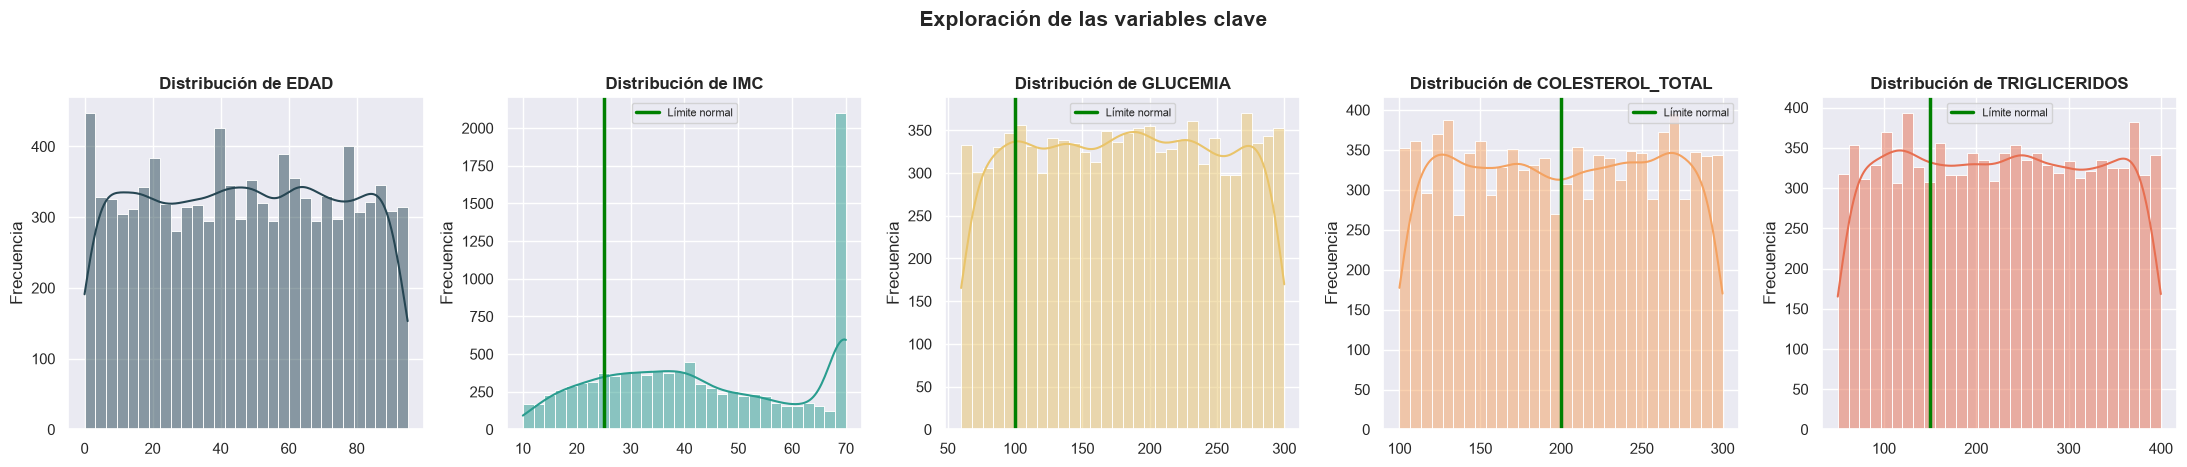

In [7]:
VARIABLES_MODELO = ["EDAD", "IMC", "GLUCEMIA", "COLESTEROL_TOTAL", "TRIGLICERIDOS"]  # las 5 variables que usará K-Means
LIMITE_NORMAL = {"IMC": 25, "GLUCEMIA": 100, "COLESTEROL_TOTAL": 200, "TRIGLICERIDOS": 150}  # tope de lo normal en cada variable
PALETA_HIST = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51"]  # un color distinto por histograma
fig, ejes = plt.subplots(1, 5, figsize=(22, 4.5))  # una fila con 5 gráficos
for eje, variable, color in zip(ejes, VARIABLES_MODELO, PALETA_HIST):  # recorre eje, variable y color a la vez
    sns.histplot(datos[variable], bins=30, color=color, kde=True, ax=eje)  # histograma con curva de densidad
    if variable in LIMITE_NORMAL:  # solo si esa variable tiene un límite normal definido
        eje.axvline(LIMITE_NORMAL[variable], color="green", linewidth=2.5, label="Límite normal")  # línea vertical verde
        eje.legend(fontsize=8)  # leyenda de la línea
    eje.set_title(f"Distribución de {variable}", fontweight="bold")  # título de cada gráfico
    eje.set_xlabel("")  # quita el rótulo del eje X (el título ya lo dice)
    eje.set_ylabel("Frecuencia")  # rótulo del eje Y
plt.suptitle("Exploración de las variables clave", fontsize=15, fontweight="bold", y=1.03)  # título general
plt.tight_layout()  # evita que los gráficos se encimen
plt.show()  # muestra la figura

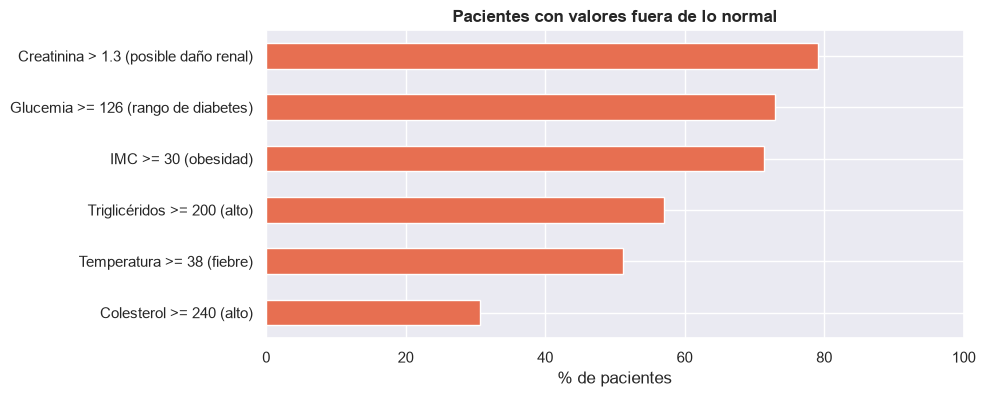

,% pacientes
IMC >= 30 (obesidad),71.4
Glucemia >= 126 (rango de diabetes),73.0
Colesterol >= 240 (alto),30.7
Triglicéridos >= 200 (alto),57.0
Creatinina > 1.3 (posible daño renal),79.1
Temperatura >= 38 (fiebre),51.1


In [8]:
reglas_riesgo = {  # nombre de la regla -> condición que la cumple
    "IMC >= 30 (obesidad)": datos["IMC"] >= 30,  # obesidad según OMS
    "Glucemia >= 126 (rango de diabetes)": datos["GLUCEMIA"] >= 126,  # glucemia en ayunas compatible con diabetes
    "Colesterol >= 240 (alto)": datos["COLESTEROL_TOTAL"] >= 240,  # colesterol total alto
    "Triglicéridos >= 200 (alto)": datos["TRIGLICERIDOS"] >= 200,  # triglicéridos altos
    "Creatinina > 1.3 (posible daño renal)": datos["CREATININA"] > 1.3,  # sobre el tope habitual en varones
    "Temperatura >= 38 (fiebre)": datos["TEMPERATURA_C"] >= 38,  # fiebre
}  # cierra el diccionario de reglas
pct_riesgo = pd.Series({regla: cond.mean() * 100 for regla, cond in reglas_riesgo.items()}).round(1)  # % de pacientes que cumple cada regla
pct_riesgo.sort_values().plot(kind="barh", color="#E76F51", figsize=(9, 4))  # barras horizontales ordenadas
plt.xlabel("% de pacientes")  # rótulo del eje X
plt.xlim(0, 100)  # eje de 0 a 100 %
plt.title("Pacientes con valores fuera de lo normal", fontweight="bold")  # título
plt.show()  # muestra el gráfico
pct_riesgo.to_frame("% pacientes")  # también la muestra como tabla

**Interpretación:** los histogramas son **planos**: cada valor aparece casi la misma cantidad de veces, algo típico de datos generados al azar. Además, casi todos los pacientes tienen valores de riesgo: 7 de cada 10 están en rango de diabetes, 8 de cada 10 tendrían daño renal y la mitad tiene fiebre. En un hospital real esto es muy poco probable.

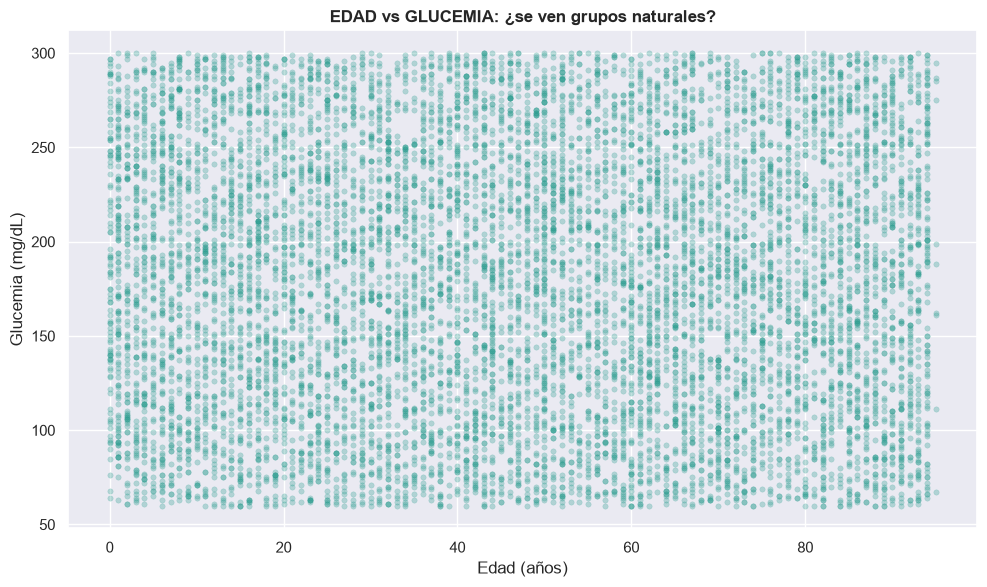

In [9]:
plt.figure(figsize=(10, 6))  # crea una figura nueva
sns.scatterplot(data=datos, x="EDAD", y="GLUCEMIA", alpha=0.3, s=15, color="#2A9D8F", edgecolor=None)  # nube de puntos edad vs glucemia
plt.title("EDAD vs GLUCEMIA: ¿se ven grupos naturales?", fontweight="bold")  # título
plt.xlabel("Edad (años)")  # rótulo del eje X
plt.ylabel("Glucemia (mg/dL)")  # rótulo del eje Y
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra el gráfico

**Interpretación:** los puntos llenan todo el gráfico de forma pareja. **No se ven grupos naturales**: la glucemia no cambia con la edad.

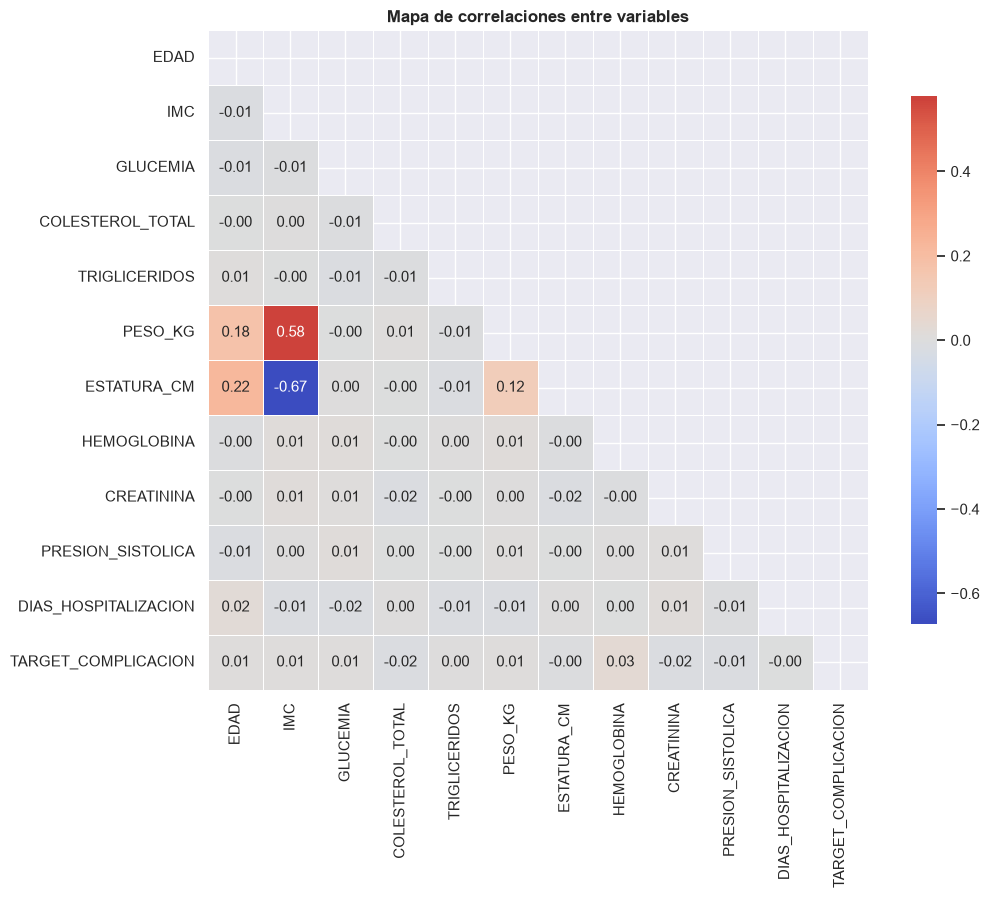

Cerca de +1: correlación positiva fuerte | cerca de -1: negativa fuerte | cerca de 0: sin relación


In [10]:
vars_corr = VARIABLES_MODELO + ["PESO_KG", "ESTATURA_CM", "HEMOGLOBINA", "CREATININA", "PRESION_SISTOLICA", "DIAS_HOSPITALIZACION", "TARGET_COMPLICACION"]  # variables a correlacionar
matriz_corr = datos[vars_corr].corr()  # coeficiente de correlación de Pearson entre cada par
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))  # máscara para ocultar el triángulo superior (repetido)
plt.figure(figsize=(11, 9))  # figura grande
sns.heatmap(matriz_corr, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})  # mapa de calor con los números
plt.title("Mapa de correlaciones entre variables", fontweight="bold")  # título
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra el gráfico
print("Cerca de +1: correlación positiva fuerte | cerca de -1: negativa fuerte | cerca de 0: sin relación")  # guía de lectura

**Interpretación:** casi todas las correlaciones son cercanas a 0, es decir, las variables no tienen relación entre sí. Solo el IMC se relaciona con el peso y la estatura, porque se calcula con ellos. Las complicaciones (`TARGET_COMPLICACION`) no se relacionan con ninguna variable clínica.

---
## Paso 4: Calidad e inconsistencias de los datos

Se revisa si los datos tienen **sentido médico**: diagnósticos que no corresponden al sexo o a la edad, medidas físicas imposibles y laboratorios que no cuadran con el diagnóstico.

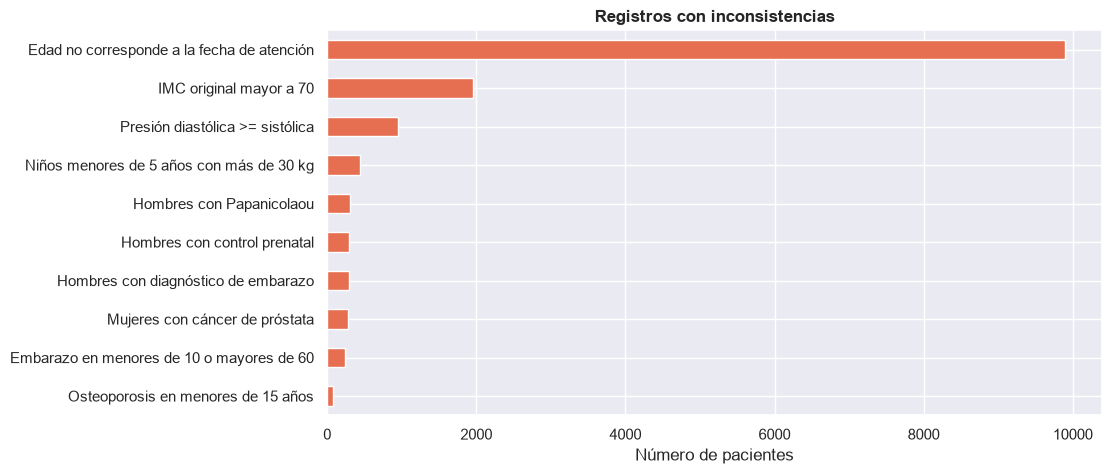

,Pacientes
Osteoporosis en menores de 15 años,78
Embarazo en menores de 10 o mayores de 60,233
Mujeres con cáncer de próstata,275
Hombres con diagnóstico de embarazo,286
Hombres con control prenatal,298
Hombres con Papanicolaou,310
Niños menores de 5 años con más de 30 kg,441
Presión diastólica >= sistólica,956
IMC original mayor a 70,1956
Edad no corresponde a la fecha de atención,9899


In [11]:
es_hombre = datos["SEXO"].eq("M")  # True para pacientes masculinos
es_mujer = datos["SEXO"].eq("F")  # True para pacientes femeninas
def con_enfermedad(nombre):  # función: ¿el paciente tiene esa enfermedad en su lista?
    return datos["ENFERMEDADES"].str.contains(nombre, regex=False)  # busca el texto exacto dentro de ENFERMEDADES
medida = datos["MEDIDA_PREVENCION"]  # atajo a la columna de medidas de prevención
fecha_nac = pd.to_datetime(datos["FECHA_NACIMIENTO"], dayfirst=True)  # convierte la fecha de nacimiento (día primero)
fecha_reg = pd.to_datetime(datos["FECHA_REGISTRO"], dayfirst=True)  # convierte la fecha de atención (día primero)
edad_en_atencion = ((fecha_reg - fecha_nac).dt.days / 365.25).astype(int)  # edad real el día que lo atendieron
conteo_incons = pd.Series({  # cuenta registros imposibles por tipo
    "Hombres con diagnóstico de embarazo": (es_hombre & con_enfermedad("Embarazo")).sum(),  # imposible biológicamente
    "Mujeres con cáncer de próstata": (es_mujer & con_enfermedad("Cancer de Prostata")).sum(),  # la próstata no existe en mujeres
    "Hombres con Papanicolaou": (es_hombre & medida.eq("Papanicolaou")).sum(),  # examen de cuello uterino
    "Hombres con control prenatal": (es_hombre & medida.eq("Control Prenatal")).sum(),  # control de embarazo
    "Embarazo en menores de 10 o mayores de 60": (con_enfermedad("Embarazo") & ~datos["EDAD"].between(10, 60)).sum(),  # edades improbables
    "Osteoporosis en menores de 15 años": (con_enfermedad("Osteoporosis") & (datos["EDAD"] < 15)).sum(),  # enfermedad de adultos mayores
    "Niños menores de 5 años con más de 30 kg": ((datos["EDAD"] < 5) & (datos["PESO_KG"] > 30)).sum(),  # peso irreal
    "IMC original mayor a 70": (datos["IMC_BRUTO"] > 70).sum(),  # IMC fuera de lo humanamente posible
    "Presión diastólica >= sistólica": (datos["PRESION_DIASTOLICA"] >= datos["PRESION_SISTOLICA"]).sum(),  # la baja no puede igualar a la alta
    "Edad no corresponde a la fecha de atención": ((datos["EDAD"] - edad_en_atencion).abs() > 1).sum(),  # edad mal calculada
}).sort_values()  # ordena de menor a mayor
conteo_incons.plot(kind="barh", color="#E76F51", figsize=(10, 5))  # gráfico de barras horizontales
plt.xlabel("Número de pacientes")  # rótulo del eje X
plt.title("Registros con inconsistencias", fontweight="bold")  # título
plt.show()  # muestra el gráfico
conteo_incons.to_frame("Pacientes")  # y también la tabla

**Interpretación:** se encontraron registros **imposibles**:
- Hombres embarazados, con Papanicolaou o con control prenatal, y mujeres con cáncer de próstata.
- Embarazos en niñas menores de 10 años o en mujeres mayores de 60, y osteoporosis en niños.
- 441 niños menores de 5 años pesan más de 30 kg, y 1,956 pacientes tenían un IMC mayor a 70.
- 956 pacientes tienen la presión diastólica (número de abajo) igual o mayor que la sistólica.
- La EDAD no corresponde a la fecha de atención: está calculada al año 2026 (ver abajo).

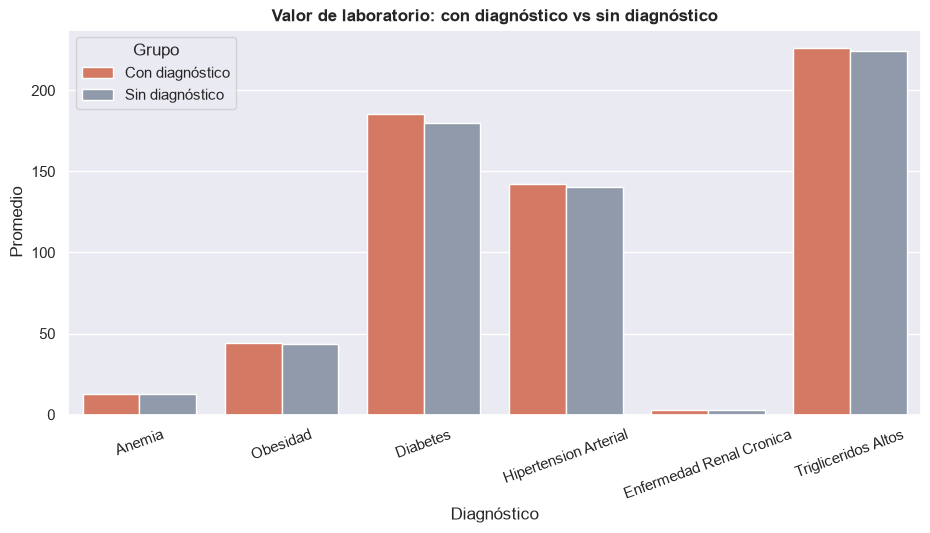

,Diagnóstico,Examen,Con diagnóstico,Sin diagnóstico
0,Anemia,HEMOGLOBINA,12.8,13.0
1,Obesidad,IMC,43.9,43.6
2,Diabetes,GLUCEMIA,185.4,180.1
3,Hipertension Arterial,PRESION_SISTOLICA,142.1,140.1
4,Enfermedad Renal Cronica,CREATININA,2.7,2.6
5,Trigliceridos Altos,TRIGLICERIDOS,226.2,224.6


In [12]:
pares_dx_lab = [  # (diagnóstico, examen que debería cambiar)
    ("Anemia", "HEMOGLOBINA"),  # anemia debería bajar la hemoglobina
    ("Obesidad", "IMC"),  # obesidad debería subir el IMC
    ("Diabetes", "GLUCEMIA"),  # diabetes debería subir la glucemia
    ("Hipertension Arterial", "PRESION_SISTOLICA"),  # hipertensión debería subir la presión
    ("Enfermedad Renal Cronica", "CREATININA"),  # enfermedad renal debería subir la creatinina
    ("Trigliceridos Altos", "TRIGLICERIDOS"),  # el diagnóstico debería reflejarse en los triglicéridos
]  # cierra la lista de pares
filas_dx = []  # aquí se acumulan los resultados
for dx, examen in pares_dx_lab:  # recorre cada par
    tiene_dx = con_enfermedad(dx)  # máscara: pacientes con ese diagnóstico
    filas_dx.append({  # agrega una fila de resultados
        "Diagnóstico": dx,  # nombre del diagnóstico
        "Examen": examen,  # examen comparado
        "Con diagnóstico": datos.loc[tiene_dx, examen].mean(),  # promedio entre quienes sí lo tienen
        "Sin diagnóstico": datos.loc[~tiene_dx, examen].mean(),  # promedio entre quienes no lo tienen
    })  # cierra la fila
tabla_dx = pd.DataFrame(filas_dx).round(1)  # convierte la lista en tabla
largo = tabla_dx.melt(id_vars=["Diagnóstico", "Examen"], var_name="Grupo", value_name="Promedio")  # formato largo para graficar
plt.figure(figsize=(11, 5))  # figura
sns.barplot(data=largo, x="Diagnóstico", y="Promedio", hue="Grupo", palette=["#E76F51", "#8D99AE"])  # barras con y sin diagnóstico
plt.xticks(rotation=20)  # inclina los nombres del eje X
plt.title("Valor de laboratorio: con diagnóstico vs sin diagnóstico", fontweight="bold")  # título
plt.show()  # muestra el gráfico
tabla_dx  # y la tabla con los números

In [13]:
datos.groupby("SEXO")[["ESTATURA_CM", "PESO_KG", "HEMOGLOBINA"]].mean().round(1)  # promedios por sexo: en la realidad difieren

,ESTATURA_CM,PESO_KG,HEMOGLOBINA
SEXO,,,
F,145.5,91.8,13.1
M,145.6,91.3,13.0


In [14]:
es_nino = datos["EDAD"] < 12  # True para menores de 12 años
print("Niños < 12 con maestría o doctorado :", (es_nino & datos["NIVEL_EDUCATIVO"].isin(["Maestria", "Doctorado"])).sum())  # estudios imposibles
print("Niños < 12 jubilados                :", (es_nino & datos["OCUPACION"].eq("Jubilado/a")).sum())  # ocupación imposible
print("Menores de 15 casados o viudos      :", ((datos["EDAD"] < 15) & datos["ESTADO_CIVIL"].isin(["Casado/a", "Viudo/a"])).sum())  # estado civil imposible
edad_a_2026 = ((pd.Timestamp("2026-01-01") - fecha_nac).dt.days / 365.25).astype(int)  # edad calculada al 1 de enero de 2026
coincide_2026 = ((datos["EDAD"] - edad_a_2026).abs() <= 1).mean() * 100  # % de registros cuya EDAD coincide con esa fecha
print(f"\nLa EDAD coincide con la edad al 2026 en el {coincide_2026:.0f}% de los registros")  # resultado
print(f"Fechas de atención: {fecha_reg.min().date()} a {fecha_reg.max().date()}")  # rango real de atenciones
print("Observación presente en los registros:", datos["OBSERVACIONES"].unique()[0])  # texto repetido en todos

Niños < 12 con maestría o doctorado : 0
Niños < 12 jubilados                : 0
Menores de 15 casados o viudos      : 0

La EDAD coincide con la edad al 2026 en el 100% de los registros
Fechas de atención: 2020-01-01 a 2024-12-05
Observación presente en los registros: Registro generado automaticamente por el Banco Nacional de Salud de Bolivia


**Interpretación:**
- **El diagnóstico no cambia el laboratorio:** en el gráfico, las barras de "con diagnóstico" y "sin diagnóstico" son casi iguales. Un paciente con anemia tiene la misma hemoglobina que uno sin anemia (12.8 vs 13.0). En datos reales la diferencia sería grande; además la OMS define anemia por debajo de 120 g/L (12 g/dL) en mujeres y 130 g/L (13 g/dL) en hombres de 15 a 65 años [9].
- **Hombres y mujeres son iguales** en estatura, peso y hemoglobina. En la realidad, los hombres son más altos y tienen más hemoglobina, y también más creatinina por su mayor masa muscular [8].
- **Los datos sociales sí son coherentes:** no hay niños con doctorado, jubilados ni casados. Quien generó la base cuidó las reglas sociales, pero no las médicas.
- La EDAD está calculada al 2026 aunque las atenciones son de 2020–2024, y todos los registros dicen *"generado automáticamente"*.

**Conclusión del paso:** hay evidencia fuerte de que el dataset es **simulado**, no de un hospital real.

---
## Paso 5: Preprocesamiento

### ¿Por qué preprocesar?
K-Means agrupa usando **distancias**. Si una variable tiene valores grandes (triglicéridos: 50–400) y otra pequeños (IMC: 10–70), la grande dominaría el resultado; por eso los algoritmos basados en distancia requieren normalizar los datos [13], [15].

### Solución: StandardScaler
Transforma cada variable para que tenga **media = 0** y **desviación = 1**:

$$z = \frac{x - \mu}{\sigma}$$

### Variables seleccionadas para el clustering
| Variable | Justificación |
|---|---|
| `EDAD` | Factor de riesgo general |
| `IMC` | Resume peso y estatura (por eso no se usan esas dos) [1] |
| `GLUCEMIA` | Azúcar en sangre (diabetes) [3] |
| `COLESTEROL_TOTAL` | Riesgo cardiovascular [5] |
| `TRIGLICERIDOS` | Grasas en sangre [5] |

No se usan datos personales (nombre, CI, teléfono) ni `COMPLICACIONES`.

In [15]:
X = datos[VARIABLES_MODELO].copy()  # copia solo las 5 variables del modelo
print(f"Datos para K-Means: {X.shape[0]:,} pacientes x {X.shape[1]} variables")  # tamaño de la matriz
print(f"Vacíos restantes: {int(X.isna().sum().sum())}")  # K-Means no admite vacíos: debe ser 0
X.describe().round(2)  # estadísticas de las variables seleccionadas

Datos para K-Means: 10,000 pacientes x 5 variables
Vacíos restantes: 0


,EDAD,IMC,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,46.94,43.58,180.30,199.84,224.72
std,27.55,18.72,69.11,58.44,101.27
min,0.00,10.00,60.00,100.00,50.00
25%,23.00,28.10,121.00,149.00,136.00
50%,47.00,41.00,181.00,200.00,225.00
75%,71.00,62.50,239.00,251.00,312.00
max,95.00,70.00,300.00,300.00,400.00


In [16]:
escalador = StandardScaler()  # crea el estandarizador: z = (x - media) / desviación
X_esc = pd.DataFrame(escalador.fit_transform(X), columns=VARIABLES_MODELO, index=X.index)  # aprende media y desviación y transforma
resumen_antes = X.agg(["mean", "std", "min", "max"]).round(2)  # resumen antes de escalar
resumen_despues = X_esc.agg(["mean", "std", "min", "max"]).round(2)  # resumen después de escalar
print("ANTES (valores originales):")  # encabezado
print(resumen_antes.to_string())  # tabla antes
print("\nDESPUÉS (valores escalados):")  # encabezado
print(resumen_despues.to_string())  # tabla después
print("\nAhora las 5 variables tienen media = 0 y desviación = 1")  # conclusión

ANTES (valores originales):
       EDAD    IMC  GLUCEMIA  COLESTEROL_TOTAL  TRIGLICERIDOS
mean  46.94  43.58    180.30            199.84         224.72
std   27.55  18.72     69.11             58.44         101.27
min    0.00  10.00     60.00            100.00          50.00
max   95.00  70.00    300.00            300.00         400.00

DESPUÉS (valores escalados):
      EDAD   IMC  GLUCEMIA  COLESTEROL_TOTAL  TRIGLICERIDOS
mean  0.00  0.00      0.00              0.00           0.00
std   1.00  1.00      1.00              1.00           1.00
min  -1.70 -1.79     -1.74             -1.71          -1.73
max   1.74  1.41      1.73              1.71           1.73

Ahora las 5 variables tienen media = 0 y desviación = 1


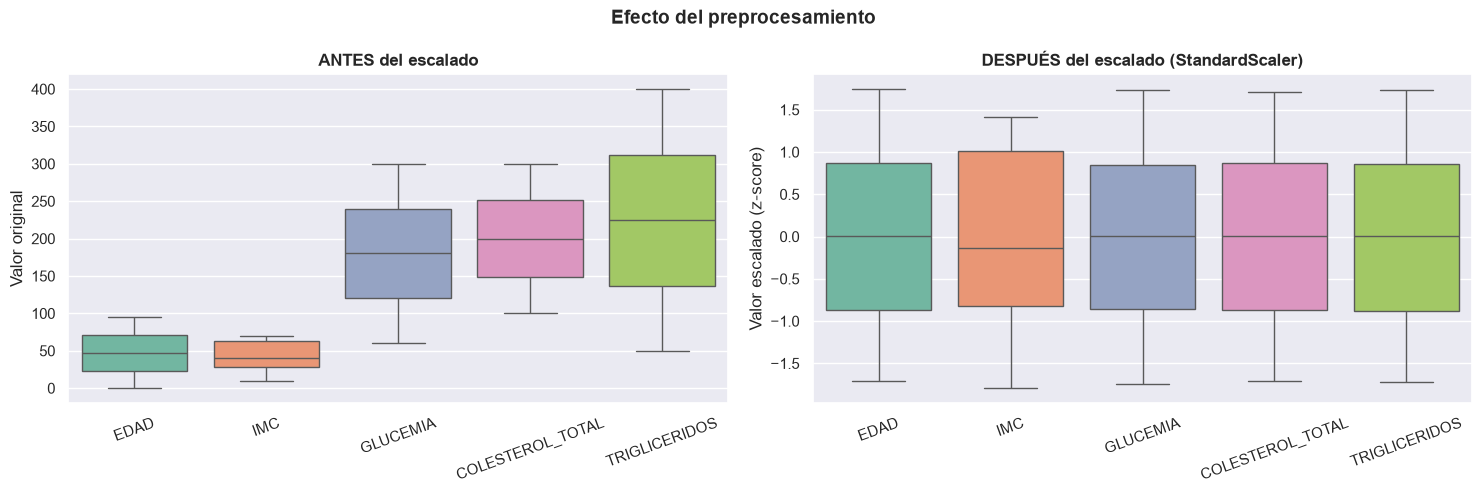

In [17]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))  # dos gráficos lado a lado
sns.boxplot(data=X, ax=ejes[0], palette="Set2")  # cajas con los valores originales
ejes[0].set_title("ANTES del escalado", fontweight="bold")  # título izquierdo
ejes[0].set_ylabel("Valor original")  # rótulo Y izquierdo
sns.boxplot(data=X_esc, ax=ejes[1], palette="Set2")  # cajas con los valores estandarizados
ejes[1].set_title("DESPUÉS del escalado (StandardScaler)", fontweight="bold")  # título derecho
ejes[1].set_ylabel("Valor escalado (z-score)")  # rótulo Y derecho
for eje in ejes:  # recorre ambos ejes
    eje.tick_params(axis="x", rotation=20)  # inclina los nombres de las variables
plt.suptitle("Efecto del preprocesamiento", fontsize=14, fontweight="bold")  # título general
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra la figura

**Interpretación:** antes del escalado, los triglicéridos y la glucemia tenían valores mucho más grandes que el IMC o la edad. Después, las 5 variables están en la misma escala, así que K-Means les da la misma importancia.

---
## Paso 6: Implementación de K-Means

### ¿Cómo elegir el número de clusters K?

**1. Método del codo**
- Se prueba K de 2 a 10 y se calcula el **WCSS** (dispersión de los puntos dentro de cada grupo) [14].
- Se busca el **"codo"**: el punto donde agregar más clusters ya no mejora mucho.

**2. Silhouette Score** [11], [12]
- Mide qué tan separados están los clusters.
- Va de **-1 a 1**; más cerca de 1 es mejor.

In [18]:
RANGO_K = list(range(2, 11))  # probaremos K = 2, 3, ..., 10
resultados_k = []  # aquí se guardan WCSS y silueta de cada K
for k in RANGO_K:  # recorre cada número de grupos
    modelo_k = KMeans(n_clusters=k, random_state=SEED_ALEATORIA, n_init=10)  # K-Means con k grupos y 10 inicios distintos
    etiquetas_k = modelo_k.fit_predict(X_esc)  # entrena y devuelve el grupo de cada paciente
    resultados_k.append({  # guarda las métricas de este K
        "K": k,  # número de grupos probado
        "WCSS": modelo_k.inertia_,  # suma de distancias al cuadrado dentro de los grupos (inercia)
        "SILUETA": silhouette_score(X_esc, etiquetas_k),  # separación entre grupos (de -1 a 1)
    })  # cierra el diccionario
eval_k = pd.DataFrame(resultados_k).set_index("K")  # tabla indexada por K
print(eval_k.round(4).to_string())  # imprime la tabla completa

          WCSS  SILUETA
K                      
2   42429.4188   0.1499
3   37385.4923   0.1450
4   34052.6002   0.1471
5   31097.6915   0.1496
6   28759.9942   0.1554
7   26964.5612   0.1562
8   25311.0655   0.1623
9   23715.4129   0.1674
10  22383.9724   0.1729


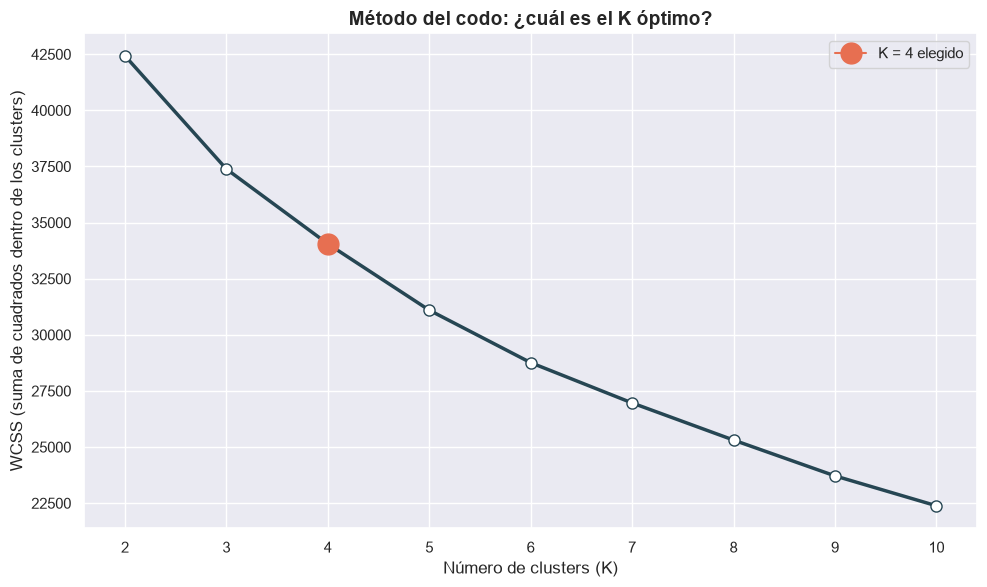

In [19]:
K_ELEGIDO = 4  # K elegido: se justifica en la interpretación de abajo
plt.figure(figsize=(10, 6))  # figura
plt.plot(eval_k.index, eval_k["WCSS"], marker="o", linewidth=2.5, color="#264653", markerfacecolor="white", markersize=8)  # curva del codo
plt.plot(K_ELEGIDO, eval_k.loc[K_ELEGIDO, "WCSS"], marker="o", markersize=15, color="#E76F51", label=f"K = {K_ELEGIDO} elegido")  # punto resaltado
plt.title("Método del codo: ¿cuál es el K óptimo?", fontsize=14, fontweight="bold")  # título
plt.xlabel("Número de clusters (K)")  # rótulo X
plt.ylabel("WCSS (suma de cuadrados dentro de los clusters)")  # rótulo Y
plt.xticks(RANGO_K)  # muestra todos los K en el eje X
plt.legend()  # leyenda
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra el gráfico

**Interpretación:** la curva baja de forma suave y **no tiene un codo marcado**. La caída más fuerte está entre K = 2 y K = 4; desde ahí baja más lento. Por eso K = 4 es una opción razonable.

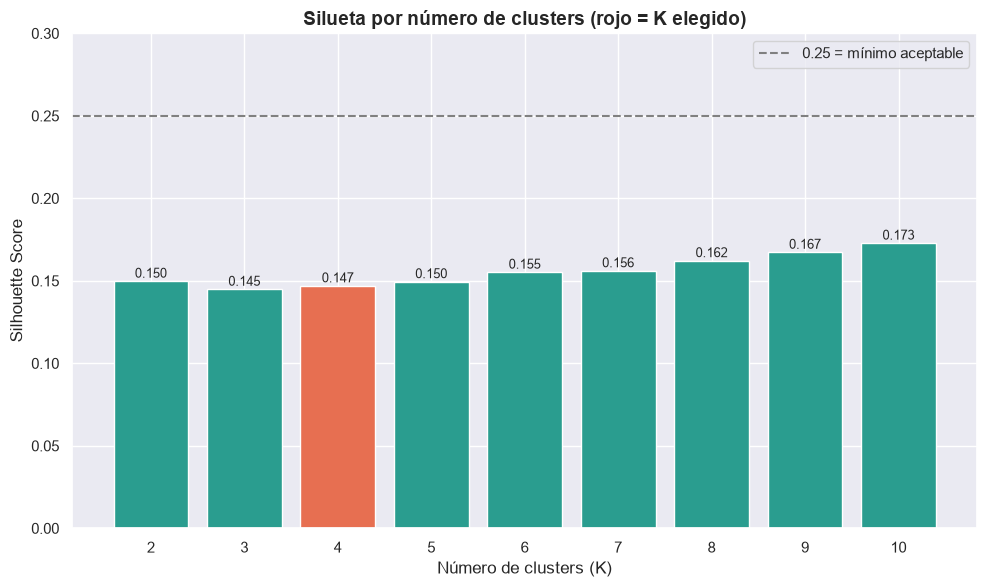

K con mayor silueta: 10 (0.173)
Silueta con K = 4: 0.147


In [20]:
mejor_k = int(eval_k["SILUETA"].idxmax())  # K con la silueta más alta
colores_barras = ["#E76F51" if k == K_ELEGIDO else "#2A9D8F" for k in eval_k.index]  # rojo para el K elegido
plt.figure(figsize=(10, 6))  # figura
barras = plt.bar(eval_k.index, eval_k["SILUETA"], color=colores_barras, edgecolor="white")  # barras de silueta por K
for barra, valor in zip(barras, eval_k["SILUETA"]):  # recorre cada barra con su valor
    plt.text(barra.get_x() + barra.get_width() / 2, valor + 0.002, f"{valor:.3f}", ha="center", fontsize=9)  # escribe el valor sobre la barra
plt.axhline(0.25, color="gray", linestyle="--", label="0.25 = mínimo aceptable")  # línea de referencia
plt.title("Silueta por número de clusters (rojo = K elegido)", fontsize=14, fontweight="bold")  # título
plt.xlabel("Número de clusters (K)")  # rótulo X
plt.ylabel("Silhouette Score")  # rótulo Y
plt.xticks(RANGO_K)  # muestra todos los K
plt.ylim(0, 0.3)  # escala del eje Y
plt.legend()  # leyenda
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra el gráfico
print(f"K con mayor silueta: {mejor_k} ({eval_k['SILUETA'].max():.3f})")  # mejor K según silueta
print(f"Silueta con K = {K_ELEGIDO}: {eval_k.loc[K_ELEGIDO, 'SILUETA']:.3f}")  # silueta del K elegido

**Interpretación:** la silueta es casi la misma para todos los K (entre 0.145 y 0.173) y siempre está por debajo de 0.25. Con K = 10 sube un poco solo porque los grupos se vuelven más pequeños, no porque sean mejores. Se elige **K = 4** porque la silueta es casi igual y 4 grupos se pueden interpretar mejor.

### Entrenar el modelo K-Means con K = 4

Parámetros:
- `n_clusters=4`: se quieren 4 grupos de pacientes.
- `random_state=42`: semilla para que el resultado sea siempre el mismo.
- `n_init=10`: el algoritmo se ejecuta 10 veces con distintos centros iniciales y se queda con el mejor.

In [21]:
modelo_final = KMeans(n_clusters=K_ELEGIDO, random_state=SEED_ALEATORIA, n_init=10)  # modelo definitivo con 4 grupos
datos["CLUSTER"] = modelo_final.fit_predict(X_esc)  # asigna a cada paciente su grupo (0 a 3)
print(f"Modelo entrenado con K = {K_ELEGIDO} | WCSS final: {modelo_final.inertia_:,.2f}\n")  # resumen del entrenamiento
tamanos = datos["CLUSTER"].value_counts().sort_index()  # pacientes por grupo
for numero, cantidad in tamanos.items():  # recorre cada grupo
    porcentaje = cantidad / len(datos) * 100  # porcentaje del total
    print(f"   Cluster {numero}: {cantidad:5,} pacientes ({porcentaje:4.1f}%) {'#' * int(porcentaje / 2)}")  # línea con barra de texto

Modelo entrenado con K = 4 | WCSS final: 34,052.60

   Cluster 0: 2,168 pacientes (21.7%) ##########
   Cluster 1: 2,808 pacientes (28.1%) ##############
   Cluster 2: 2,772 pacientes (27.7%) #############
   Cluster 3: 2,252 pacientes (22.5%) ###########


### Nombre de cada cluster

Se revisa el **centro (promedio) de cada cluster** y se le da un nombre. Los nombres se asignan con reglas, para que no cambien si K-Means numera los grupos en otro orden:
- el cluster con **mayor edad** = adultos mayores;
- el cluster con **menor edad** = jóvenes;
- de los dos restantes, el de **mayor colesterol** = colesterol alto.

In [22]:
centros = datos.groupby("CLUSTER")[VARIABLES_MODELO].mean().round(1)  # promedio real de cada variable en cada grupo
joven = centros["EDAD"].idxmin()  # grupo con la edad promedio más baja
mayor = centros["EDAD"].idxmax()  # grupo con la edad promedio más alta
intermedios = centros.drop(index=[joven, mayor])  # los dos grupos restantes (adultos)
col_normal = intermedios["COLESTEROL_TOTAL"].idxmin()  # de los dos, el de colesterol más bajo
col_alto = intermedios["COLESTEROL_TOTAL"].idxmax()  # y el de colesterol más alto
NOMBRE_POR_CLUSTER = {  # número de grupo -> nombre (asignado por reglas, no a mano)
    joven: "Jóvenes con IMC extremo",  # el más joven
    col_normal: "Adultos con colesterol normal",  # adulto con colesterol bajo
    col_alto: "Adultos con colesterol alto",  # adulto con colesterol alto
    mayor: "Adultos mayores con IMC extremo",  # el de mayor edad
}  # cierra el diccionario
ORDEN_SEG = ["Jóvenes con IMC extremo", "Adultos con colesterol normal", "Adultos con colesterol alto", "Adultos mayores con IMC extremo"]  # orden fijo para tablas y gráficos
COLOR_SEG = dict(zip(ORDEN_SEG, ["#F4A261", "#2A9D8F", "#E76F51", "#264653"]))  # un color por segmento
datos["SEGMENTO"] = pd.Categorical(datos["CLUSTER"].map(NOMBRE_POR_CLUSTER), categories=ORDEN_SEG, ordered=True)  # columna con el nombre del segmento
for numero in sorted(NOMBRE_POR_CLUSTER):  # recorre los grupos en orden numérico
    print(f"   Cluster {numero} -> {NOMBRE_POR_CLUSTER[numero]}")  # muestra la equivalencia

   Cluster 0 -> Jóvenes con IMC extremo
   Cluster 1 -> Adultos con colesterol alto
   Cluster 2 -> Adultos con colesterol normal
   Cluster 3 -> Adultos mayores con IMC extremo


---
## Paso 7: Visualización de los clusters

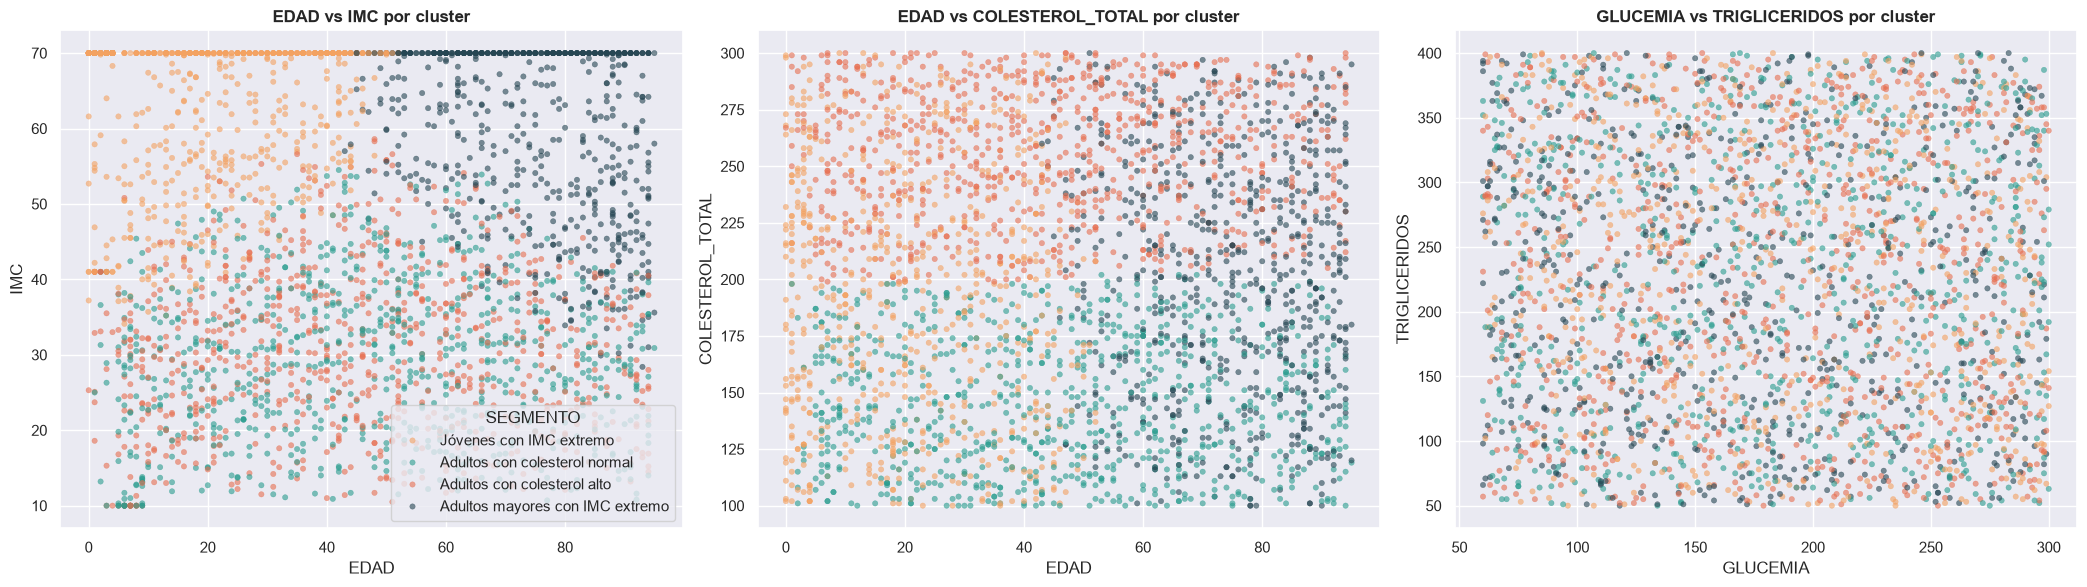

In [23]:
muestra = datos.sample(3000, random_state=SEED_ALEATORIA)  # muestra de 3000 pacientes para que el gráfico se vea claro
pares_xy = [("EDAD", "IMC"), ("EDAD", "COLESTEROL_TOTAL"), ("GLUCEMIA", "TRIGLICERIDOS")]  # tres combinaciones de variables
fig, ejes = plt.subplots(1, 3, figsize=(21, 6))  # tres gráficos en una fila
for eje, (var_x, var_y) in zip(ejes, pares_xy):  # recorre cada eje con su par de variables
    sns.scatterplot(data=muestra, x=var_x, y=var_y, hue="SEGMENTO", hue_order=ORDEN_SEG, palette=COLOR_SEG, alpha=0.6, s=15, edgecolor=None, ax=eje, legend="auto" if var_y == "IMC" else False)  # puntos coloreados por segmento (leyenda solo en el primero)
    eje.set_title(f"{var_x} vs {var_y} por cluster", fontweight="bold")  # título de cada gráfico
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra la figura

**Interpretación:**
- **EDAD vs IMC:** se ve claramente la separación. Arriba a la izquierda están los jóvenes con IMC extremo, arriba a la derecha los adultos mayores con IMC extremo y abajo los adultos con IMC más bajo.
- **EDAD vs COLESTEROL:** los dos grupos de adultos se separan por colesterol: alto y normal.
- **GLUCEMIA vs TRIGLICÉRIDOS:** los colores están mezclados. Estas dos variables **no separan** los grupos.

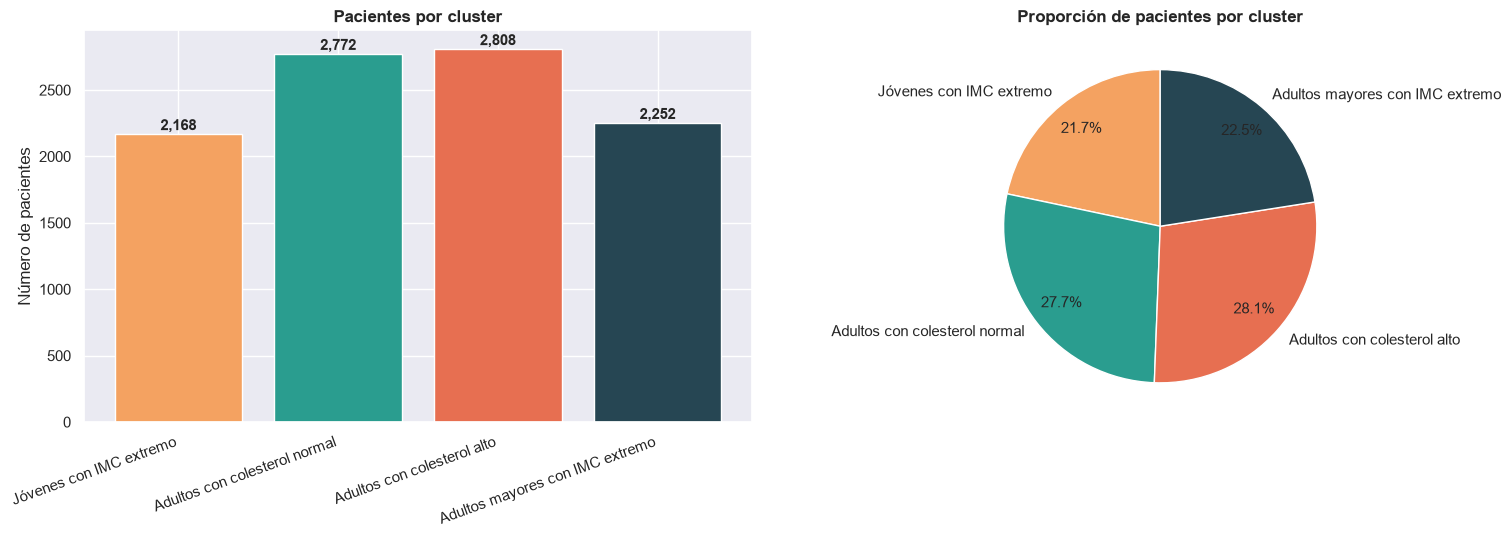

In [24]:
pacientes_seg = datos["SEGMENTO"].value_counts().reindex(ORDEN_SEG)  # pacientes por segmento en el orden fijo
colores_seg = [COLOR_SEG[s] for s in ORDEN_SEG]  # lista de colores en ese mismo orden
fig, ejes = plt.subplots(1, 2, figsize=(16, 5.5))  # barras a la izquierda y torta a la derecha
ejes[0].bar(range(K_ELEGIDO), pacientes_seg.values, color=colores_seg, edgecolor="white")  # barras de cantidad
ejes[0].set_xticks(range(K_ELEGIDO))  # posiciones de las etiquetas
ejes[0].set_xticklabels(ORDEN_SEG, rotation=20, ha="right")  # nombres de los segmentos
ejes[0].set_title("Pacientes por cluster", fontweight="bold")  # título
ejes[0].set_ylabel("Número de pacientes")  # rótulo Y
for i, valor in enumerate(pacientes_seg.values):  # recorre cada barra
    ejes[0].text(i, valor + 30, f"{valor:,}", ha="center", fontweight="bold")  # escribe la cantidad encima
ejes[1].pie(pacientes_seg.values, labels=ORDEN_SEG, colors=colores_seg, autopct="%1.1f%%", startangle=90, pctdistance=0.8)  # torta de proporciones
ejes[1].set_title("Proporción de pacientes por cluster", fontweight="bold")  # título
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra la figura

**Interpretación:** los 4 grupos tienen tamaños parecidos (entre 22 % y 28 %). Ninguno es demasiado pequeño, así que todos se pueden analizar.

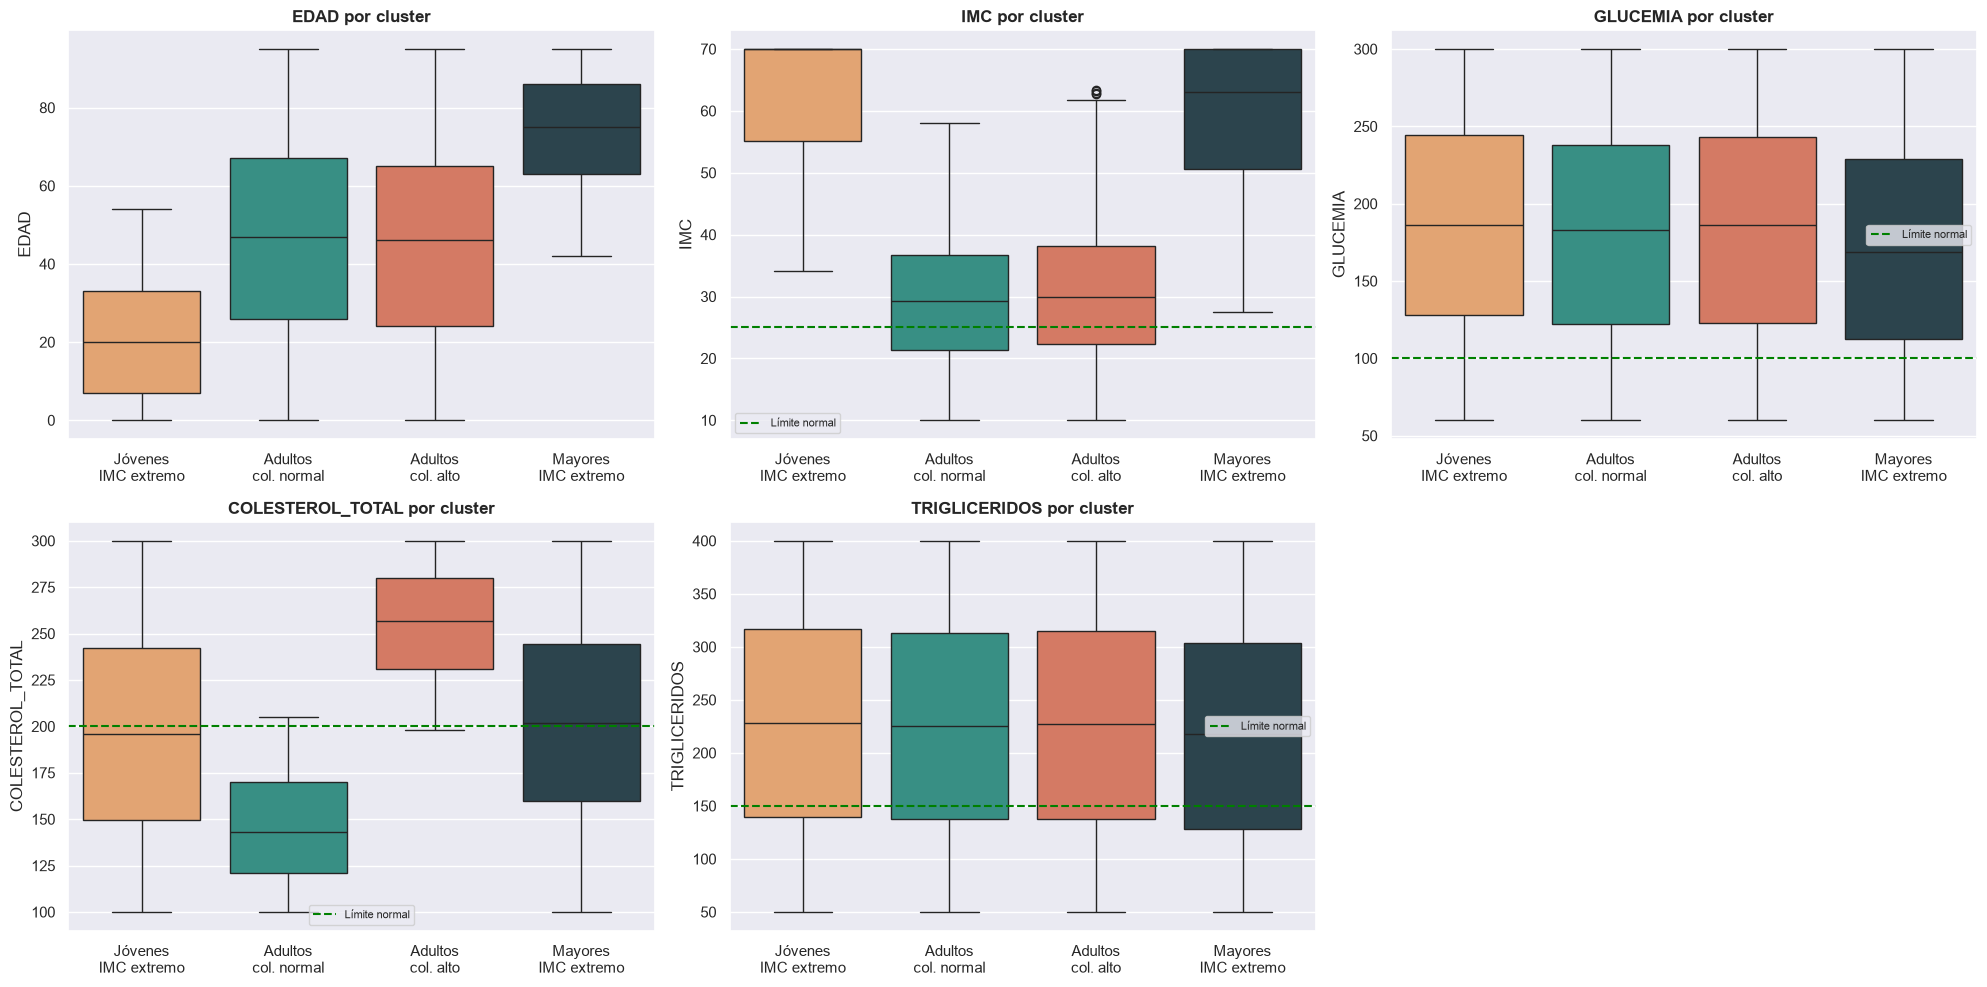

In [25]:
fig, ejes = plt.subplots(2, 3, figsize=(20, 10))  # cuadrícula de 2 filas x 3 columnas
etiquetas_cortas = ["Jóvenes\nIMC extremo", "Adultos\ncol. normal", "Adultos\ncol. alto", "Mayores\nIMC extremo"]  # nombres cortos para el eje X
for eje, variable in zip(ejes.flat, VARIABLES_MODELO):  # un gráfico por variable
    sns.boxplot(data=datos, x="SEGMENTO", y=variable, order=ORDEN_SEG, palette=COLOR_SEG, ax=eje)  # cajas de la variable por segmento
    eje.set_title(f"{variable} por cluster", fontweight="bold")  # título
    eje.set_xlabel("")  # sin rótulo X
    eje.set_xticks(range(K_ELEGIDO))  # fija las posiciones de las etiquetas
    eje.set_xticklabels(etiquetas_cortas)  # pone los nombres cortos
    if variable in LIMITE_NORMAL:  # si hay límite normal para esa variable
        eje.axhline(LIMITE_NORMAL[variable], color="green", linestyle="--", label="Límite normal")  # línea horizontal verde
        eje.legend(fontsize=8)  # leyenda
ejes.flat[-1].axis("off")  # el sexto espacio queda vacío
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra la figura

**Interpretación:**
- **EDAD, IMC y COLESTEROL** son las variables que diferencian a los grupos: sus cajas están en niveles distintos.
- **GLUCEMIA y TRIGLICÉRIDOS** tienen cajas casi iguales en los 4 grupos, y todas están por encima de la línea verde (límite normal).
- Los dos grupos de IMC extremo tienen la caja casi pegada a 70, por los valores imposibles que se recortaron.

---
## Paso 8: Perfilado de clusters

El perfilado **describe** las características promedio de cada cluster para darle un **nombre y personalidad** que ayude a tomar decisiones en el hospital.

In [26]:
perfil = datos.groupby("SEGMENTO", observed=True)[VARIABLES_MODELO].mean().round(2)  # promedio de cada variable por segmento
print("Perfil promedio de cada cluster:\n")  # encabezado
print(perfil.to_string())  # imprime la tabla

Perfil promedio de cada cluster:

                                  EDAD    IMC  GLUCEMIA  COLESTEROL_TOTAL  TRIGLICERIDOS
SEGMENTO                                                                                
Jóvenes con IMC extremo          20.65  62.48    185.09            195.79         227.26
Adultos con colesterol normal    46.96  29.27    180.58            145.70         225.69
Adultos con colesterol alto      45.58  30.35    183.00            255.05         226.70
Adultos mayores con IMC extremo  73.90  59.47    171.99            201.54         218.61


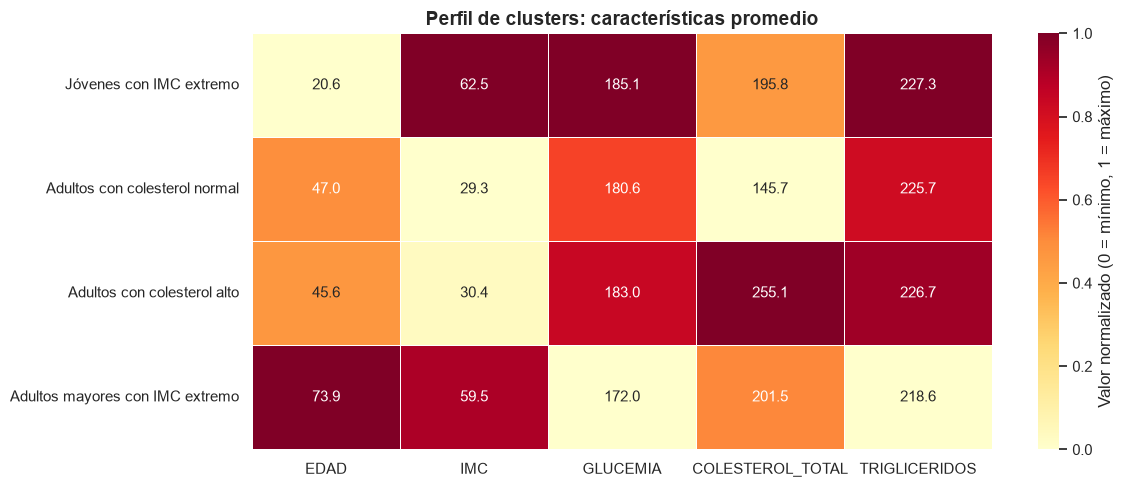

In [27]:
perfil_0a1 = (perfil - perfil.min()) / (perfil.max() - perfil.min())  # lleva cada columna a escala 0 (mínimo) a 1 (máximo)
plt.figure(figsize=(12, 5))  # figura
sns.heatmap(perfil_0a1, annot=perfil, fmt=".1f", cmap="YlOrRd", linewidths=0.5, cbar_kws={"label": "Valor normalizado (0 = mínimo, 1 = máximo)"})  # color por escala 0-1, número real encima
plt.title("Perfil de clusters: características promedio", fontsize=14, fontweight="bold")  # título
plt.ylabel("")  # sin rótulo Y
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra el gráfico

In [28]:
REFERENCIAS = {  # texto del valor normal de cada variable (ver bibliografía)
    "IMC": "normal 18.5 - 24.9",  # rango habitual de IMC en adultos
    "GLUCEMIA": "normal 70 - 99",  # rango habitual en ayunas
    "COLESTEROL_TOTAL": "normal < 200",  # colesterol total deseable
    "TRIGLICERIDOS": "normal < 150",  # triglicéridos normales
}  # cierra el diccionario
print("INTERPRETACIÓN DE LOS CLUSTERS\n" + "=" * 55)  # título del bloque
for segmento in ORDEN_SEG:  # recorre cada segmento
    fila = perfil.loc[segmento]  # promedios del segmento
    n_seg = int((datos["SEGMENTO"] == segmento).sum())  # cuántos pacientes tiene
    print(f"\n  {segmento}: {n_seg:,} pacientes ({n_seg / len(datos) * 100:.1f}%)")  # nombre y tamaño
    print(f"    {'EDAD':17s}: {fila['EDAD']:6.1f}  (años)")  # edad
    for variable, texto in REFERENCIAS.items():  # recorre las 4 variables con referencia
        print(f"    {variable:17s}: {fila[variable]:6.1f}  ({texto})")  # valor del grupo junto a su referencia

INTERPRETACIÓN DE LOS CLUSTERS

  Jóvenes con IMC extremo: 2,168 pacientes (21.7%)
    EDAD             :   20.6  (años)
    IMC              :   62.5  (normal 18.5 - 24.9)
    GLUCEMIA         :  185.1  (normal 70 - 99)
    COLESTEROL_TOTAL :  195.8  (normal < 200)
    TRIGLICERIDOS    :  227.3  (normal < 150)

  Adultos con colesterol normal: 2,772 pacientes (27.7%)
    EDAD             :   47.0  (años)
    IMC              :   29.3  (normal 18.5 - 24.9)
    GLUCEMIA         :  180.6  (normal 70 - 99)
    COLESTEROL_TOTAL :  145.7  (normal < 200)
    TRIGLICERIDOS    :  225.7  (normal < 150)

  Adultos con colesterol alto: 2,808 pacientes (28.1%)
    EDAD             :   45.6  (años)
    IMC              :   30.4  (normal 18.5 - 24.9)
    GLUCEMIA         :  183.0  (normal 70 - 99)
    COLESTEROL_TOTAL :  255.1  (normal < 200)
    TRIGLICERIDOS    :  226.7  (normal < 150)

  Adultos mayores con IMC extremo: 2,252 pacientes (22.5%)
    EDAD             :   73.9  (años)
    IMC        

### Etiquetas de los clusters

| Nombre | Descripción |
|---|---|
| **Jóvenes con IMC extremo** | 21 años e IMC 62.5 en promedio. El 46 % son menores de edad, con 102 kg y 1.13 m en promedio. No es un perfil médico real: es el efecto de pesos y estaturas generados por separado. |
| **Adultos con colesterol normal** | 47 años, colesterol 146 e IMC 29. Es el grupo con menos colesterol (menos de 200 mg/dL es lo deseable [5]), aunque igual tiene la glucemia alta (181). |
| **Adultos con colesterol alto** | 46 años, colesterol 255 e IMC 30. Supera el umbral de 240 mg/dL considerado alto [6]; tienen riesgo cardiovascular. Es el grupo con más sentido médico. |
| **Adultos mayores con IMC extremo** | 74 años e IMC 59.5. El 93 % tiene obesidad mórbida (IMC de 40 o más), algo muy improbable en la realidad. |

### ¿Cómo usaría el hospital esta segmentación?

- **Jóvenes con IMC extremo:** revisar cómo se registran el peso y la talla; programa de nutrición infantil y juvenil.
- **Adultos con colesterol normal:** controles de rutina; vigilar la glucemia.
- **Adultos con colesterol alto:** control de lípidos, dieta y evaluación cardiológica.
- **Adultos mayores con IMC extremo:** verificar los datos; control geriátrico de peso, presión y glucosa.

---
## Paso 9: Comparación de los clusters con otras variables

Se usan variables que **no entraron al modelo** para ver si los grupos se diferencian en algo importante para el hospital. Aquí se responde la pregunta del proyecto: **¿algún grupo tiene más complicaciones?**

In [29]:
datos["NIVEL_BAJO"] = datos["NIVEL_SOCIOECONOMICO"].str.contains("Nivel 1|Nivel 2")  # True si vive en pobreza o pobreza extrema
comparacion = datos.groupby("SEGMENTO", observed=True).agg(  # resume cada segmento con varias medidas
    Pacientes=("CLUSTER", "size"),  # cantidad de pacientes
    Complicacion_pct=("TARGET_COMPLICACION", "mean"),  # proporción con complicación
    Internados_pct=("INTERNADO", "mean"),  # proporción internada
    Fallecidos_pct=("ESTADO_PACIENTE", lambda s: s.eq("Fallecido").mean()),  # proporción fallecida
    Criticos_pct=("ESTADO_PACIENTE", lambda s: s.eq("Critico").mean()),  # proporción en estado crítico
    Pobreza_pct=("NIVEL_BAJO", "mean"),  # proporción en pobreza
    Enfermedades_prom=("NUM_ENFERMEDADES", "mean"),  # promedio de enfermedades por paciente
)  # cierra la agregación
columnas_pct = [c for c in comparacion.columns if c.endswith("_pct")]  # columnas que están en proporción
comparacion[columnas_pct] = comparacion[columnas_pct] * 100  # las pasa a porcentaje
comparacion.round(1)  # muestra la tabla redondeada

,Pacientes,Complicacion_pct,Internados_pct,Fallecidos_pct,Criticos_pct,Pobreza_pct,Enfermedades_prom
SEGMENTO,,,,,,,
Jóvenes con IMC extremo,2168,87.6,10.7,1.8,5.2,37.3,2.5
Adultos con colesterol normal,2772,88.2,11.4,2.1,5.6,33.9,2.5
Adultos con colesterol alto,2808,87.6,11.6,2.1,5.4,36.7,2.5
Adultos mayores con IMC extremo,2252,87.9,12.3,2.0,3.9,36.3,2.5


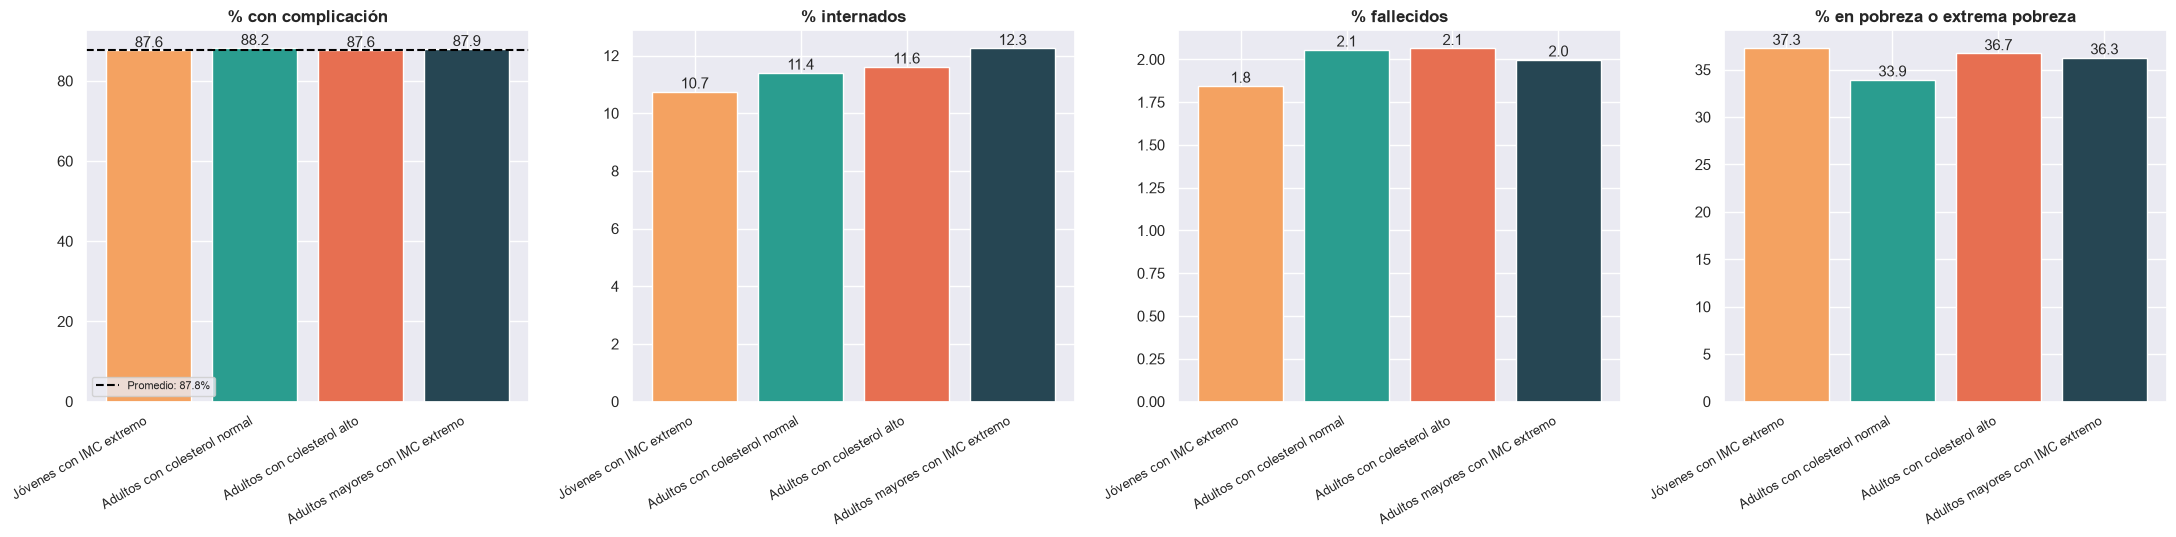

In [30]:
indicadores = [("Complicacion_pct", "% con complicación"), ("Internados_pct", "% internados"), ("Fallecidos_pct", "% fallecidos"), ("Pobreza_pct", "% en pobreza o extrema pobreza")]  # (columna, título)
fig, ejes = plt.subplots(1, 4, figsize=(22, 5.5))  # cuatro gráficos en fila
for eje, (columna, titulo) in zip(ejes, indicadores):  # recorre cada indicador
    eje.bar(range(K_ELEGIDO), comparacion[columna], color=colores_seg)  # barras por segmento
    eje.set_xticks(range(K_ELEGIDO))  # posiciones de etiquetas
    eje.set_xticklabels(ORDEN_SEG, rotation=30, ha="right", fontsize=9)  # nombres de segmentos
    eje.set_title(titulo, fontweight="bold")  # título
    for i, valor in enumerate(comparacion[columna]):  # recorre cada barra
        eje.text(i, valor, f"{valor:.1f}", ha="center", va="bottom")  # escribe el porcentaje encima
ejes[0].axhline(tasa_global, color="black", linestyle="--", label=f"Promedio: {tasa_global:.1f}%")  # línea del promedio general
ejes[0].legend(fontsize=8)  # leyenda de esa línea
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra la figura

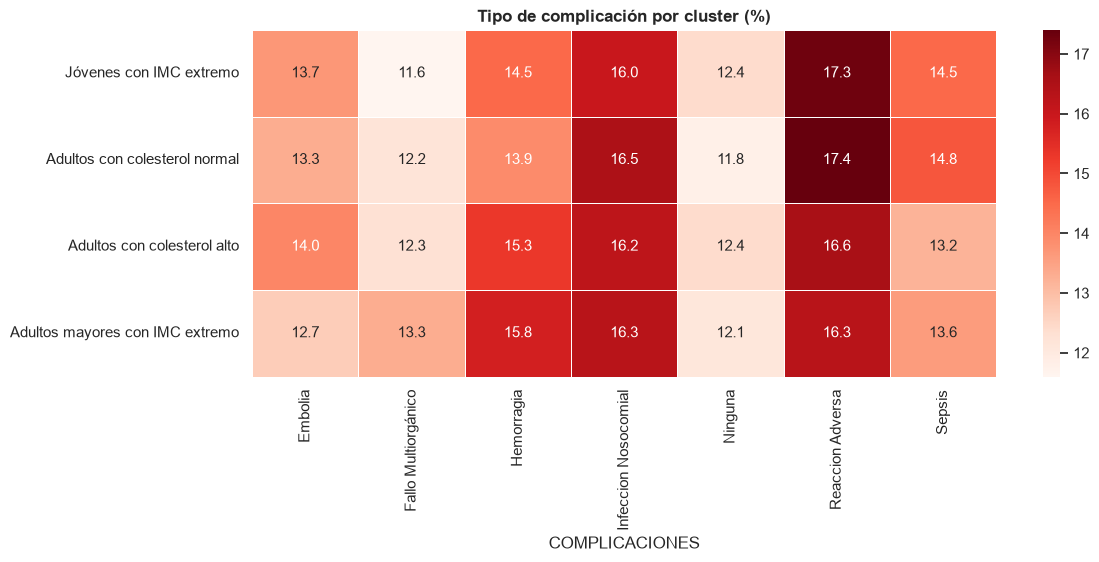

In [31]:
tipo_compl = pd.crosstab(datos["SEGMENTO"], datos["COMPLICACIONES"], normalize="index").mul(100).round(1)  # % de cada tipo de complicación dentro de cada segmento
plt.figure(figsize=(12, 4.5))  # figura
sns.heatmap(tipo_compl, annot=True, fmt=".1f", cmap="Reds", linewidths=0.5)  # mapa de calor con los porcentajes
plt.title("Tipo de complicación por cluster (%)", fontweight="bold")  # título
plt.ylabel("")  # sin rótulo Y
plt.show()  # muestra el gráfico

In [32]:
datos["DX_OBESIDAD"] = datos["ENFERMEDADES"].str.contains("Obesidad").astype(int)  # 1 si tiene diagnóstico de obesidad
datos.groupby("SEGMENTO", observed=True).agg(  # compara IMC real con diagnóstico registrado
    IMC_promedio=("IMC", "mean"),  # IMC promedio del segmento
    Con_diagnostico_obesidad_pct=("DX_OBESIDAD", lambda s: s.mean() * 100),  # % con diagnóstico de obesidad
).round(1)  # redondea a un decimal

,IMC_promedio,Con_diagnostico_obesidad_pct
SEGMENTO,,
Jóvenes con IMC extremo,62.5,4.9
Adultos con colesterol normal,29.3,5.1
Adultos con colesterol alto,30.4,4.8
Adultos mayores con IMC extremo,59.5,4.4


**Interpretación:**
- **Complicaciones:** los 4 grupos tienen casi la misma tasa (87.6 % a 88.2 %), igual al promedio (87.8 %). El tipo de complicación también se reparte casi igual. El perfil metabólico **no explica** quién tiene complicaciones.
- **Internación:** sube un poco con la edad (10.7 % en jóvenes y 12.3 % en adultos mayores). Es la única tendencia lógica, pero la diferencia es pequeña.
- **Fallecidos:** los adultos mayores (2.0 %) no tienen más fallecidos que los adultos (2.1 %). En la realidad, la mortalidad sube mucho con la edad.
- **Obesidad:** los grupos con IMC promedio de 60 tienen el mismo porcentaje de diagnóstico de obesidad (≈ 5 %) que los grupos con IMC de 30. Si los datos fueran reales, casi todos tendrían ese diagnóstico, pues la OMS define obesidad desde IMC 30 [1].

---
## Paso 10: Evaluación y métricas del modelo

En clustering no hay una "respuesta correcta" para comparar. Las métricas miden la **calidad interna** de los grupos:

| Métrica | Qué mide | Mejor valor |
|---|---|---|
| **WCSS / Inercia** | Qué tan compactos son los clusters [14] | Más bajo |
| **Silhouette Score** | Separación entre clusters [11], [12] | Más cerca de 1 |

In [33]:
silueta_final = silhouette_score(X_esc, modelo_final.labels_)  # silueta promedio del modelo final
print(f"MÉTRICAS DEL MODELO K-MEANS (K = {K_ELEGIDO})\n" + "=" * 45)  # encabezado
print(f"  Número de clusters : {K_ELEGIDO}")  # K
print(f"  WCSS (inercia)     : {modelo_final.inertia_:,.2f}")  # compacidad
print(f"  Silhouette Score   : {silueta_final:.4f}")  # separación
print(f"  Iteraciones usadas : {modelo_final.n_iter_}")  # iteraciones hasta converger
if silueta_final > 0.7:  # tramo excelente
    veredicto = "Excelente: clusters muy bien definidos"  # texto del veredicto
elif silueta_final > 0.5:  # tramo bueno
    veredicto = "Bueno: clusters razonablemente definidos"  # texto del veredicto
elif silueta_final > 0.25:  # tramo aceptable
    veredicto = "Aceptable: hay superposición entre clusters"  # texto del veredicto
else:  # cualquier valor menor
    veredicto = "Débil: los clusters se solapan mucho"  # texto del veredicto
print(f"  Interpretación     : {veredicto}")  # imprime el veredicto

MÉTRICAS DEL MODELO K-MEANS (K = 4)
  Número de clusters : 4
  WCSS (inercia)     : 34,052.60
  Silhouette Score   : 0.1471
  Iteraciones usadas : 43
  Interpretación     : Débil: los clusters se solapan mucho


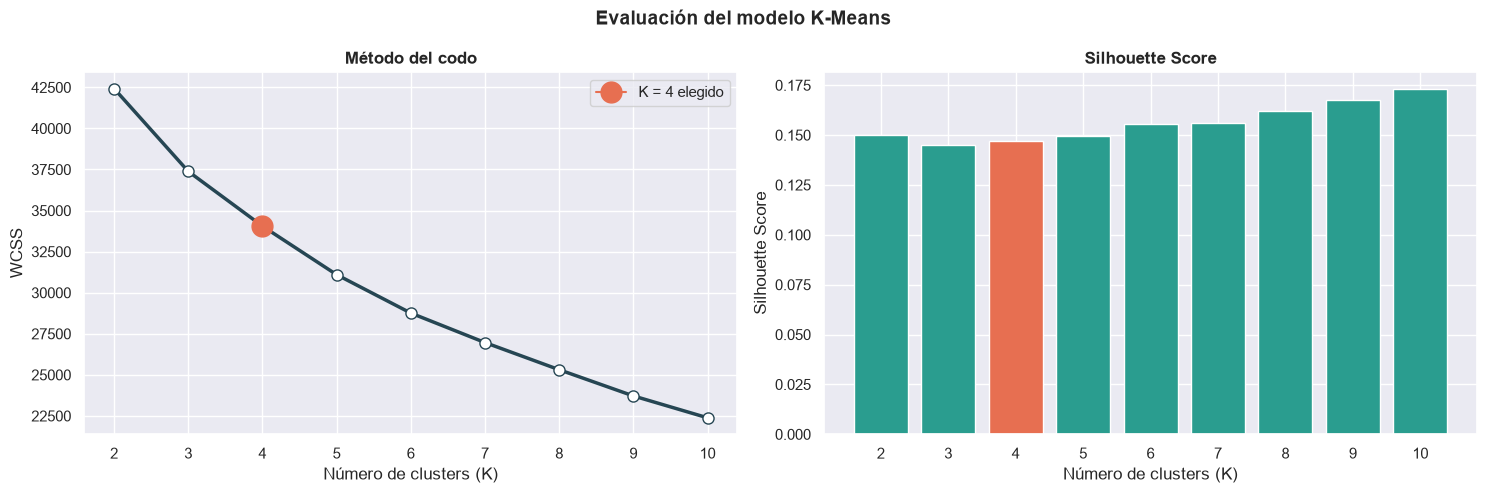

In [34]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))  # dos gráficos: codo y silueta
ejes[0].plot(eval_k.index, eval_k["WCSS"], marker="o", linewidth=2.5, color="#264653", markerfacecolor="white", markersize=8)  # curva del codo
ejes[0].plot(K_ELEGIDO, eval_k.loc[K_ELEGIDO, "WCSS"], marker="o", markersize=15, color="#E76F51", label=f"K = {K_ELEGIDO} elegido")  # K elegido
ejes[0].set_title("Método del codo", fontweight="bold")  # título izquierdo
ejes[0].set_xlabel("Número de clusters (K)")  # rótulo X
ejes[0].set_ylabel("WCSS")  # rótulo Y
ejes[0].set_xticks(RANGO_K)  # todos los K
ejes[0].legend()  # leyenda
ejes[1].bar(eval_k.index, eval_k["SILUETA"], color=colores_barras, edgecolor="white")  # barras de silueta
ejes[1].set_title("Silhouette Score", fontweight="bold")  # título derecho
ejes[1].set_xlabel("Número de clusters (K)")  # rótulo X
ejes[1].set_ylabel("Silhouette Score")  # rótulo Y
ejes[1].set_xticks(RANGO_K)  # todos los K
plt.suptitle("Evaluación del modelo K-Means", fontsize=14, fontweight="bold")  # título general
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra la figura

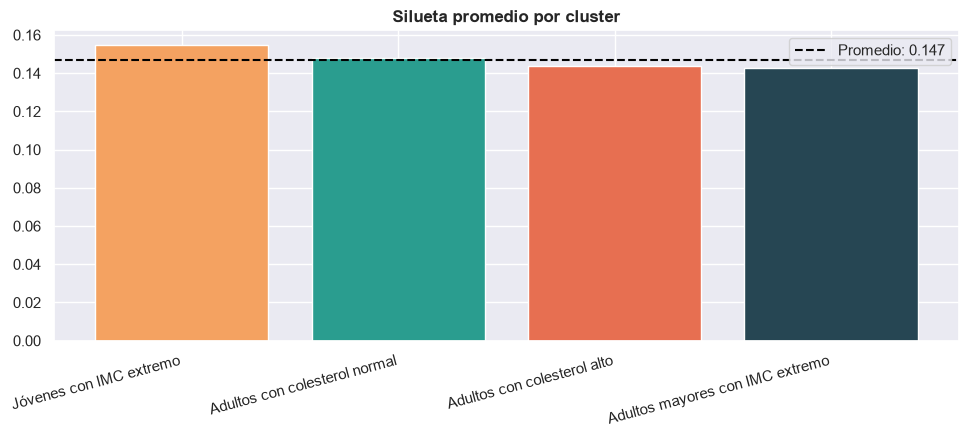

In [35]:
sil_paciente = pd.Series(silhouette_samples(X_esc, modelo_final.labels_), index=datos.index)  # silueta de cada paciente
sil_por_seg = sil_paciente.groupby(datos["SEGMENTO"], observed=True).mean().reindex(ORDEN_SEG)  # promedio por segmento
plt.figure(figsize=(10, 4.5))  # figura
plt.bar(range(K_ELEGIDO), sil_por_seg.values, color=colores_seg)  # barras por segmento
plt.xticks(range(K_ELEGIDO), ORDEN_SEG, rotation=15, ha="right")  # nombres de segmentos
plt.axhline(silueta_final, color="black", linestyle="--", label=f"Promedio: {silueta_final:.3f}")  # línea del promedio
plt.title("Silueta promedio por cluster", fontweight="bold")  # título
plt.legend()  # leyenda
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra el gráfico

**Interpretación:** la silueta de **0.147** es **débil** (menor a 0.25): los grupos existen, pero se mezclan entre sí. Los 4 clusters tienen una calidad parecida. No es un error del modelo: pasa porque las variables no tienen relación entre ellas, como se vio en los Pasos 3 y 4.

---
## Paso 11: Conclusiones

1. **Se formaron 4 perfiles de pacientes:** jóvenes con IMC extremo, adultos con colesterol normal, adultos con colesterol alto y adultos mayores con IMC extremo. Las variables que más los separan son la edad, el IMC y el colesterol.
2. **Ningún grupo tiene más complicaciones** (todos ≈ 88 %). Esto coincide con la regresión logística y el árbol de decisión: las variables clínicas no explican las complicaciones.
3. **El dataset muestra inconsistencias graves:** hombres embarazados, mujeres con cáncer de próstata, niños de más de 30 kg, presiones imposibles, diagnósticos que no coinciden con el laboratorio y una edad calculada a 2026. Todo indica que los datos son **generados**, no de un hospital real.
4. **Recomendación:** para encontrar perfiles de riesgo útiles se necesitan datos clínicos reales. Con esta base, el principal hallazgo es la **falta de calidad de los datos**, lo que obliga a dudar de la fuente.

### Limitaciones de K-Means

| Limitación | Descripción |
|---|---|
| Hay que definir K | No siempre se sabe cuántos grupos buscar |
| Sensible a outliers | Un valor extremo (como un IMC de 418) puede mover un centro |
| Solo clusters esféricos | No detecta bien formas irregulares [13] |
| Depende de la calidad de los datos | Si las variables no tienen relación entre sí, los grupos salen débiles |

In [36]:
print("RESUMEN FINAL: K-Means y perfiles de pacientes hospitalarios\n" + "=" * 60)  # encabezado
print(f"  Dataset          : {NOMBRE_ARCHIVO}")  # archivo usado
print(f"  Registros        : {len(datos):,} pacientes")  # cantidad de filas
print(f"  Variables usadas : {len(VARIABLES_MODELO)} ({', '.join(VARIABLES_MODELO)})")  # variables del modelo
print(f"  K elegido        : {K_ELEGIDO} clusters")  # K
print(f"  WCSS             : {modelo_final.inertia_:,.2f}")  # inercia
print(f"  Silhouette Score : {silueta_final:.4f}")  # silueta
print(f"  Complicaciones   : {tasa_global:.2f}% (promedio general)")  # KPI
print("\n  Distribución de clusters:")  # subtítulo
for segmento in ORDEN_SEG:  # recorre cada segmento
    n_seg = int((datos["SEGMENTO"] == segmento).sum())  # pacientes del segmento
    print(f"    {segmento:33s}: {n_seg:5,} pacientes | complicación {comparacion.loc[segmento, 'Complicacion_pct']:.1f}%")  # línea resumen

RESUMEN FINAL: K-Means y perfiles de pacientes hospitalarios
  Dataset          : base_de_datos_medicina_complicaciones_modificada.xlsx
  Registros        : 10,000 pacientes
  Variables usadas : 5 (EDAD, IMC, GLUCEMIA, COLESTEROL_TOTAL, TRIGLICERIDOS)
  K elegido        : 4 clusters
  WCSS             : 34,052.60
  Silhouette Score : 0.1471
  Complicaciones   : 87.82% (promedio general)

  Distribución de clusters:
    Jóvenes con IMC extremo          : 2,168 pacientes | complicación 87.6%
    Adultos con colesterol normal    : 2,772 pacientes | complicación 88.2%
    Adultos con colesterol alto      : 2,808 pacientes | complicación 87.6%
    Adultos mayores con IMC extremo  : 2,252 pacientes | complicación 87.9%


---
# Marco teórico y bibliografía

Esta sección amplía los conceptos que aparecen en las tablas del notebook y los respalda con fuentes **en español**, consultadas y verificadas el 14 de noviembre de 2026. Las cifras clínicas son de **referencia general para adultos**; el diagnóstico individual siempre lo hace un profesional de la salud.

## A. Variables clínicas del modelo

### A.1 Triglicéridos
Los triglicéridos **no son un tipo de colesterol**: son otro tipo de grasa en la sangre que también se mide en el perfil lipídico y que puede aumentar el riesgo de enfermedad cardíaca [5].

| Categoría | Valor (mg/dL) | Fuente |
|---|---|---|
| Normal / deseable | menos de 150 | [5], [6] |
| Límite alto | 150 – 199 | [5], [6] |
| Alto | 200 – 499 | [6] |
| Muy alto | 500 o más | [6] |

**Uso en el notebook:** línea de referencia en 150 y regla "triglicéridos ≥ 200 (alto)". Variable del modelo K-Means.

### A.2 Colesterol total
El colesterol total reúne el colesterol LDL ("malo"), el HDL ("bueno") y otros componentes; es uno de los números del perfil lipídico [5].

| Categoría | Valor (mg/dL) | Fuente |
|---|---|---|
| Deseable | menos de 200 | [5], [6] |
| Límite superior | 200 – 239 | [6] |
| Alto | 240 o más | [6] |

**Uso en el notebook:** línea de referencia en 200 y regla "colesterol ≥ 240 (alto)". Es la variable que separa a los dos grupos de adultos.

### A.3 Glucemia (glucosa en sangre)
La glucemia es la concentración de azúcar en sangre. El criterio de diagnóstico de diabetes por glucemia en ayunas es **126 mg/dL o más**; ese umbral se propuso a partir de estudios epidemiológicos que lo relacionan con la aparición de complicaciones [3]. Más adelante la ADA bajó el límite superior de lo normal en ayunas de 110 a **100 mg/dL**, lo que redefinió la "glucosa alterada en ayuno" como 100–125 mg/dL [4].

| Categoría (en ayunas) | Valor (mg/dL) | Fuente |
|---|---|---|
| Normal | menos de 100 | [4] |
| Glucosa alterada en ayuno (prediabetes) | 100 – 125 | [4] |
| Rango de diabetes | 126 o más | [3] |

**Uso en el notebook:** línea de referencia en 100 y regla "glucemia ≥ 126". La OMS ofrece además una nota descriptiva general sobre la diabetes y su diagnóstico [2].

> Nota de verificación: el límite inferior de 70 mg/dL que se usa en el texto del Paso 8 es de uso clínico habitual, pero **no apareció textualmente** en las fuentes consultadas para esta bibliografía; el umbral que sí se respalda es el superior (100 y 126).

### A.4 Índice de masa corporal (IMC)
Se calcula como peso (kg) dividido por la estatura al cuadrado (m²) y es la medida que la OMS usa para diagnosticar sobrepeso y obesidad [1].

| Categoría (adultos) | IMC | Fuente |
|---|---|---|
| Sobrepeso | 25 o más | [1] |
| Obesidad | 30 o más | [1] |

**Uso en el notebook:** línea de referencia en 25 y regla "IMC ≥ 30 (obesidad)". El límite 18.5 para "peso normal" es la clasificación OMS habitual, pero **no figura** en la nota descriptiva consultada [1]; por eso solo se respaldan formalmente los cortes de 25 y 30. En niños y adolescentes el IMC se interpreta según la edad, por lo que los cortes de adultos no aplican al grupo "Jóvenes" [1].

### A.5 Creatinina
La creatinina es un residuo de la actividad muscular que los riñones filtran y eliminan por la orina [7], [8]; si los riñones fallan, se acumula en la sangre, y un nivel anormal puede ser signo de enfermedad renal. Lo "normal" depende de la masa muscular, la dieta, la edad y la actividad [7].

| Grupo | Valor orientativo (mg/dL) | Fuente |
|---|---|---|
| Varones adultos sanos | 0.7 – 1.3 | [8] |
| Mujeres adultas sanas | 0.5 – 0.95 | [8] |

**Uso en el notebook:** la regla "creatinina > 1.3 (posible daño renal)" usa el tope masculino; en mujeres el tope es menor, por lo que el porcentaje real de valores elevados sería aún mayor. Un solo valor alto no basta para diagnosticar una enfermedad [7].

### A.6 Hemoglobina
Es la proteína de los glóbulos rojos que transporta oxígeno; su concentración es el criterio principal para definir anemia. La directriz de la OMS 2024 fija como anemia valores **menores de 120 g/L (12 g/dL) en mujeres no embarazadas** y **menores de 130 g/L (13 g/dL) en hombres**, de 15 a 65 años [9].

**Uso en el notebook:** se compara la hemoglobina de pacientes con y sin diagnóstico de anemia (Paso 4).

### A.7 Presión arterial
Se expresa como sistólica/diastólica en mmHg. La OMS define hipertensión como **140/90 mmHg o más**, confirmada con mediciones en dos días distintos [10]. En una medición válida, la presión diastólica (la "baja") es menor que la sistólica (la "alta").

**Uso en el notebook:** se separa "120/80" en dos columnas y se cuentan los registros con diastólica ≥ sistólica (956), físicamente imposibles.

## B. Conceptos de ciencia de datos

| Concepto | Qué es | Uso en el notebook | Fuente |
|---|---|---|---|
| **K-Means** | Algoritmo no supervisado que agrupa observaciones en K grupos cercanos a un centro (centroide) | Paso 6: agrupar pacientes en 4 perfiles | [13], [15] |
| **Normalización / estandarización** | Llevar las variables a una escala común; necesaria en algoritmos basados en distancia | `StandardScaler` (Paso 5) | [13], [15] |
| **WCSS (inercia)** | Suma de distancias al cuadrado de cada punto a su centroide; mide la compacidad | Método del codo (Paso 6) | [14] |
| **Método del codo** | Probar varios K y buscar donde la mejora del WCSS se aplana | Elegir K (Paso 6) | [14] |
| **Coeficiente de silueta** | Mide, de -1 a 1, qué tan bien asignado está cada dato a su grupo; cerca de 1 = bien asignado, cerca de 0 = entre dos grupos, cerca de -1 = mal asignado | Calidad de los clusters (Pasos 6 y 10) | [11], [12] |
| **Limitación de forma** | K-Means supone grupos esféricos y de tamaño parecido | Sección de limitaciones | [13] |

## C. Lista de referencias

**Organismos de salud y fuentes clínicas**

[1] Organización Mundial de la Salud (OMS). *Obesidad y sobrepeso* (nota descriptiva). Define sobrepeso (IMC ≥ 25) y obesidad (IMC ≥ 30) en adultos y el cálculo del IMC. https://www.who.int/es/news-room/fact-sheets/detail/obesity-and-overweight

[2] Organización Mundial de la Salud (OMS). *Diabetes* (nota descriptiva, 14 de noviembre de 2024). https://www.who.int/es/news-room/fact-sheets/detail/diabetes

[3] Birulés Pons M, Fernández Fernández I. *Criterios de cribado y diagnóstico de diabetes mellitus*. Atención Primaria. 2003;31(5):334-336. Documentos semFYC (Sociedad Española de Medicina de Familia y Comunitaria). https://www.elsevier.es/es-revista-atencion-primaria-27-pdf-download-13045696

[4] Revista Médica del Instituto Mexicano del Seguro Social. Artículo sobre la prevalencia de glucosa alterada en ayuno con los criterios ADA-1997 y ADA-2003 (descenso del límite normal de 110 a 100 mg/dL). https://revistamedica.imss.gob.mx/index.php/revista_medica/article/download/4052/3863/23510

[5] MedlinePlus en español, Biblioteca Nacional de Medicina de EE. UU. *Niveles de colesterol: lo que necesita saber*. https://www.medlineplus.gov/spanish/cholesterollevelswhatyouneedtoknow.html

[6] Mayo Clinic (versión en español). *Colesterol alto: diagnóstico y tratamiento*. https://mayoclinic.org/es-es/diseases-conditions/high-blood-cholesterol/diagnosis-treatment/drc-20350806

[7] MedlinePlus en español, Biblioteca Nacional de Medicina de EE. UU. *¿Qué es una prueba de creatinina?* https://www.medlineplus.gov/spanish/pruebas-de-laboratorio/prueba-de-creatinina/

[8] Clínica Universidad de Navarra. *Diccionario médico: creatinina* (valores orientativos en adultos sanos). https://www.cun.es/diccionario-medico/terminos/creatinina

[9] Fundación Bengoa. *Directriz sobre los valores de corte de hemoglobina para definir la anemia en individuos y poblaciones de la Organización Mundial de la Salud, 2024*. Anales Venezolanos de Nutrición. 2024;37(1):61-67. https://doi.org/10.54624/2024.37.1.006 · PDF: https://ve.scielo.org/pdf/avn/v37n1/0798-0752-avn-37-01-61.pdf

[10] Organización Mundial de la Salud (OMS). *Hipertensión* (nota descriptiva, 25 de septiembre de 2025). https://www.who.int/es/news-room/fact-sheets/detail/hypertension

**Estadística y aprendizaje automático**

[11] Rousseeuw PJ. *Silhouettes: a graphical aid to the interpretation and validation of cluster analysis*. Journal of Computational and Applied Mathematics. 1987;20:53-65. https://doi.org/10.1016/0377-0427(87)90125-7 *(artículo original, en inglés; es la referencia fundacional del coeficiente de silueta)*

[12] Nuevo método para el seguimiento de la evolución de los estudiantes basado en técnicas de agrupamiento (explica el coeficiente de silueta en español y su interpretación entre -1 y 1). Acofipapers. https://acofipapers.org/index.php/eiei/article/download/37/32/63

[13] DataCamp (en español). *Introducción a k-Means Clustering con scikit-learn en Python*. 3 de mayo de 2024. https://www.datacamp.com/es/tutorial/k-means-clustering-python

[14] Zilliz. *Comprender el algoritmo de agrupamiento K-means en el aprendizaje automático* (WCSS y selección de K). https://zilliz.com/es/blog/k-means-clustering

[15] OCW Universidad de Cádiz. *Ejercicio 108_01: clustering con K-medias con normalización, visualización y métricas en Python*. https://ocw.uca.es/mod/resource/view.php?id=4665

---
### Notas de verificación

- Todas las fuentes se consultaron en línea el **14/11/2026**. Las cifras de las secciones A.1 a A.7 se contrastaron con el texto de cada fuente; las dos excepciones (límite inferior de glucemia 70 mg/dL e IMC 18.5) están señaladas arriba como **no respaldadas textualmente**.
- La fuente [4] se cita por su contenido y enlace; el enlace permite comprobar título y autores exactos.
- La fuente [11] y el trabajo original de silueta están en inglés porque no existe versión original en español; [12] la explica en español.
- La regla de "fiebre ≥ 38 °C" usada en el Paso 3 no se incluyó en esta bibliografía por no haberse contrastado con una fuente en español.
- Los valores de referencia son generales para adultos y **no sustituyen** el criterio clínico.